# CITS4404 Part 2 – Design and Optimisation of an AI Trading Bot

This project implements and evaluates a Bitcoin trading bot using nature-inspired optimisation algorithms. The notebook first loads the Bitcoin data, splits it into training and test sets, and sets up the main functions for moving averages, crossover signals, and backtesting.

It then runs four optimisation algorithms: Slime Mould Algorithm, SFLA, Cuckoo Search, and PSO. The final sections compare the optimised bots with simple baselines, inspect the learned parameters, and repeat the experiment across multiple random seeds to check stability.

In [1]:
import numpy as np
import pandas as pd
import kagglehub
from pathlib import Path
import matplotlib.pyplot as plt
import time
import math

## 1. Prepare Bitcoin Dataset

We first load the Bitcoin price data and prepares the train/test split used throughout the notebook. Data before 2020 is used for training, while the data from 2020 onwards is kept for the final test.

### 1.1. Load and Split Dataset

In [2]:
path = kagglehub.dataset_download("prasoonkottarathil/btcinusd")

100%|██████████| 80.2M/80.2M [00:02<00:00, 31.3MB/s]

Extracting files...


In [3]:
Train_end = "2019-12-31"
Test_start = "2020-01-01"

data_path = Path(path)
data_mapping = {"daily": data_path / "BTC-Daily.csv", "hourly": data_path / "BTC-Hourly.csv",}


def load_btc_data(timeframe="daily"):
    df = pd.read_csv(data_mapping[timeframe])
    df.columns = df.columns.str.strip().str.lower()

    df["datetime"] = pd.to_datetime(df["date"])
    df = df.set_index("datetime").sort_index()

    df = df[["open", "high", "low", "close", "volume btc", "volume usd"]].dropna()

    print(f"Loaded with {len(df)} rows from {df.index[0].date()} to {df.index[-1].date()}")
    return df

def train_test_split(df):
    train = df.loc[:Train_end]
    test = df.loc[Test_start:]
    print(f"Train: {len(train):,} rows from {train.index[0].date()} to {train.index[-1].date()}")
    print(f"Test:  {len(test):,} rows from {test.index[0].date()} to {test.index[-1].date()}")
    return train, test

df = load_btc_data("daily")
df_train, df_test = train_test_split(df)

P_train = df_train["close"].to_numpy(float)
P_test = df_test["close"].to_numpy(float)

Loaded with 2651 rows from 2014-11-28 to 2022-03-01
Train: 1,860 rows from 2014-11-28 to 2019-12-31
Test:  791 rows from 2020-01-01 to 2022-03-01


In [4]:
print(df.head())
print("\nColumns:", list(df.columns))

              open    high     low   close  volume btc  volume usd
datetime                                                          
2014-11-28  363.59  381.34  360.57  376.28  3220878.18     8617.15
2014-11-29  376.42  386.60  372.25  376.72  2746157.05     7245.19
2014-11-30  376.57  381.99  373.32  373.34  1145566.61     3046.33
2014-12-01  376.40  382.31  373.03  378.39  2520662.37     6660.56
2014-12-02  378.39  382.86  375.23  379.25  2593576.46     6832.53

Columns: ['open', 'high', 'low', 'close', 'volume btc', 'volume usd']


After loading the Bitcoin dataset, there are 2,651 daily records from 2014-11-28 to 2022-03-01. We split the data at 2020, so the training set contains 1,860 rows up to 2019-12-31, and the final test set contains 791 rows from 2020-01-01 onwards.

- Dataset range: 2014-11-28 to 2022-03-01
- Training rows: 1,860
- Test rows: 791

This confirms that the data from 2020 onwards was kept unseen and only used for final testing.

### 1.2. Visualise BTC Price Trend

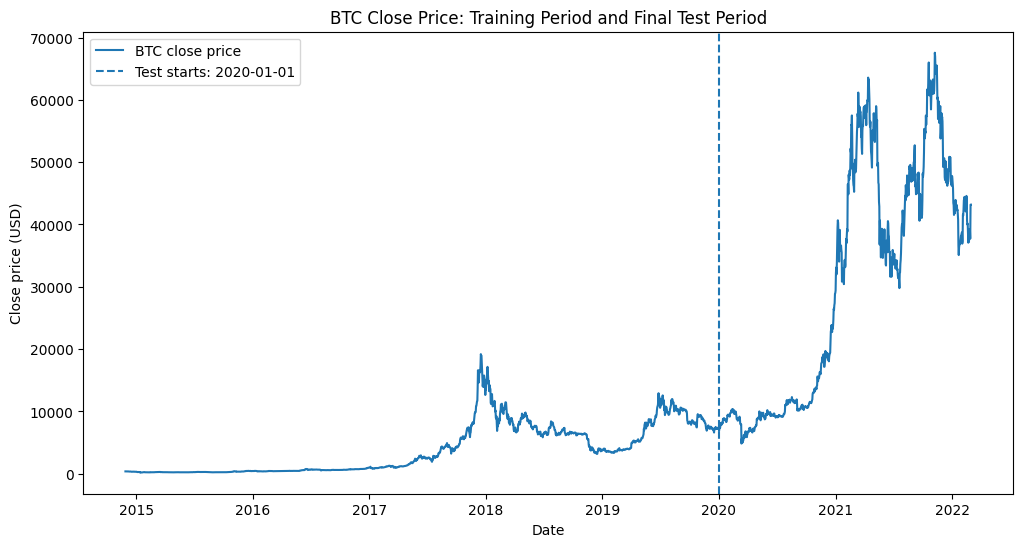

In [5]:
plt.figure(figsize=(12, 6))
plt.plot(df.index, df["close"], label="BTC close price")
plt.axvline(pd.to_datetime(Test_start), linestyle="--", label="Test starts: 2020-01-01")
plt.title("BTC Close Price: Training Period and Final Test Period")
plt.xlabel("Date")
plt.ylabel("Close price (USD)")
plt.legend()
plt.show()

The plot shows that the 2020 onwards test period behaves quite differently from the training period. BTC price rises much more sharply after 2020 and also has larger swings, so the final test set gives a harder check of whether the trained bots generalise.

## 2. Set Moving-Average Filters

The bot uses three moving-average filters: SMA, LMA, and EMA. Each one reacts to price changes in a slightly different way. The filters smooth the price data into clearer trend signals.

SMA uses a simple average, LMA gives more weight to recent prices, and EMA responds more strongly to recent data through the alpha value. Later, these filters are combined into one moving-average signal, so the optimiser can tune the weights, window sizes, and EMA alpha.

In [6]:
# Edge condition
def pad(P, N):
    N = max(1, int(N))
    padding = np.flip(P[1:N])
    return np.append(padding, P)

# Simple Moving Average: uniform weights
def sma_filter(N):
    N = max(1, int(N))
    return np.ones(N) / N

# Linear-weighted Moving Average: recent values more weight
def lma_filter(N):
    N = max(1, int(N))
    k = np.arange(N, dtype=float)
    weights = 1.0 - k / N
    weights /= weights.sum()
    return weights

# Exponential Moving Average: recent values exponentially higher weight
def ema_filter(N, alpha=0.3):
    N = max(1, int(N))
    alpha = float(np.clip(alpha, 1e-4, 1.0 - 1e-4))
    k = np.arange(N, dtype=float)
    weights = alpha * (1.0 - alpha) ** k
    s = weights.sum()
    if s == 0:
        return np.ones(N) / N
    return weights / s

# Generic weighted moving average using convolution
def wma(P, N, kernel):
    N = max(1, int(N))
    return np.convolve(pad(P, N), kernel, mode='valid')

# Weighted combination of MAs
def combined_MA(P, w1, d1, w2, d2, w3, d3, alpha3):
    w1, w2, w3 = max(0.0, w1), max(0.0, w2), max(0.0, w3)
    total_w = w1 + w2 + w3

    if total_w < 1e-9:
        w1 = w2 = w3 = 1.0
        total_w = 3.0

    sig  = w1 * wma(P, d1, sma_filter(d1))
    sig += w2 * wma(P, d2, lma_filter(d2))
    sig += w3 * wma(P, d3, ema_filter(d3, alpha3))
    return sig / total_w

## 3. Generate Crossover Signals

The trading rule is based on a fast and slow signal:

- Buy when the fast signal crosses above the slow signal
- Sell when the fast signal crosses below the slow signal

In [7]:
def crossover_filter():
    return np.array([0.5, -0.5])

# Generating +1 (buy), -1 (sell) signals from a faster and slower combined_MA
def generate_signals(P, fast_params, slow_params):
    fast = combined_MA(P, **fast_params)
    slow = combined_MA(P, **slow_params)

    diff = fast - slow
    sign_diff = np.sign(diff)

    # Convolving with crossover filter
    cross = np.convolve(pad(sign_diff, 2), crossover_filter(), mode='valid')

    # +1 where cross > 0.5 (buy)
    # -1 where cross < -0.5 (sell)
    signals = np.zeros_like(P)
    signals[cross > 0.5] = +1.0
    signals[cross < -0.5] = -1.0

    return signals

## 4. Backtesting and Evaluation Setup

### 4.1. Set the Initial Trading Conditions

The initial cash balance and transaction fee are defined in the description. The bot starts with $1000 cash, and each buy or sell transaction applies a 3% fee.

In [8]:
fee = 0.03
start_cash = 1000.0

### 4.2. Define Backtest Function

The backtest function simulates the trading bot on one Bitcoin price sequence. It follows the project rules by buying with all available cash, selling all BTC, applying transaction fees, and liquidating any remaining BTC at the final price.

In [9]:
def backtest(P, signals, fee=fee, start_cash=start_cash, verbose=False):
    cash = start_cash
    btc = 0.0
    n_buys = 0
    n_sells = 0
    equity = np.zeros(len(P))
    position = np.zeros(len(P))  # 0 = cash, 1 = holding BTC

    for t, price in enumerate(P):
        sig = signals[t]

        if sig == 1 and cash > 0 and btc == 0.0: #Buy
            btc = (cash * (1.0 - fee)) / price
            cash = 0.0
            n_buys += 1
            if verbose:
                print(f'BUY at t={t:4d} price={price:.2f} btc={btc:.6f}')

        elif sig == -1 and btc > 0 and cash == 0.0: #Sell
            cash = btc * price * (1.0 - fee)
            btc = 0.0
            n_sells += 1
            if verbose:
                print(f'SELL at t={t:4d} price={price:.2f} cash={cash:.2f}')

        equity[t] = cash + btc * price
        position[t] = 1 if btc > 0 else 0

    # Liquidate remaining BTC at the end
    if btc > 0:
        cash = btc * P[-1] * (1.0 - fee)
        btc = 0.0

    equity[-1] = cash
    position[-1] = 0

    return {
        'final_cash': cash,
        'n_buys': n_buys,
        'n_sells': n_sells,
        'equity_curve': equity,
        'position': position,
    }

### 4.3. Define the Buy-and-Hold Baseline

A buy-and-hold baseline is used for comparison. This buys BTC at the first price, holds it until the end, and then sells it using the same fee rule as the trading bot.

In [10]:
# Baseline buying at t=0 and selling at the end
def buy_and_hold(P, fee=fee, start_cash=start_cash):
    btc = (start_cash * (1.0 - fee)) / P[0]
    cash = btc * P[-1] * (1.0 - fee)
    return cash

# Equity curve for Buy-and-Hold
def buy_and_hold_curve(P, fee=fee, start_cash=start_cash):
    btc = (start_cash * (1.0 - fee)) / P[0]
    curve = btc * P
    curve[-1] = curve[-1] * (1.0 - fee)
    return curve

### 4.4. Calculate Analysis Metrics

Additional metrics are calculated for analysis. The optimiser still uses final cash as the fitness value, but final cash alone does not explain the behaviour of the strategy. The extra metrics show the return, comparison with buy-and-hold, maximum drawdown, market exposure, and number of trades, which helps evaluate whether the result is actually reliable.

In [11]:
#  Extra metrics for analysis only
def calculate_analysis_metrics(P, backtest_result, fee=fee, start_cash=start_cash):
    equity = backtest_result['equity_curve']
    final_cash = backtest_result['final_cash']
    bnh = buy_and_hold(P, fee=fee, start_cash=start_cash)

    total_return_pct = (final_cash / start_cash - 1.0) * 100

    running_max = np.maximum.accumulate(equity)
    drawdowns = (equity - running_max) / np.maximum(running_max, 1e-12)
    max_drawdown_pct = drawdowns.min() * 100

    exposure_pct = np.mean(backtest_result['position']) * 100

    return {
        'Final Cash': final_cash,
        'Return (%)': total_return_pct,
        'Buy-and-Hold': bnh,
        'vs BnH (%)': (final_cash / bnh) * 100 if bnh != 0 else np.nan,
        'Max Drawdown (%)': max_drawdown_pct,
        'Exposure (%)': exposure_pct,
        'Buys': backtest_result['n_buys'],
        'Sells': backtest_result['n_sells'],
    }

## 5. Set Up the Optimisation Problem

This section defines the optimisation problem before running the algorithms. It sets the parameter ranges, explains how each parameter vector is converted into trading signals, and defines how each solution is evaluated.

### 5.1 Define the Search Space

The search space defines what the optimiser is allowed to change. Each candidate solution contains 14 parameters for the fast and slow moving-average signals, including filter weights, window sizes, and EMA alpha values.

Two configurations are used: `sma_only` for a simple SMA strategy, and `MAs_combined` for a more flexible strategy using SMA, LMA, and EMA together.

In [12]:
# Search space configs:

#[0]  w1_fast - SMA weight
#[1]  w2_fast - LMA weight
#[2]  w3_fast - EMA weight
#[3]  d1_fast - SMA window
#[4]  d2_fast - LMA window
#[5]  d3_fast - EMA window
#[6]  a_fast - EMA alpha
#[7]  w1_slow - SMA weight
#[8]  w2_slow - LMA weight
#[9]  w3_slow - EMA weight
#[10] d1_slow - SMA window
#[11] d2_slow - LMA window
#[12] d3_slow - EMA window
#[13] a_slow - EMA alpha
# Set weight to 0 to exclude filter
# Set weight to 1 to only include that filter

CONFIGS = {
    # SMA only
    'sma_only': {
        'lb': np.array([1, 0, 0, 2, 2, 2, 0.01, 1, 0, 0, 2, 2, 2, 0.01]),
        'ub': np.array([1, 0, 0, 50, 50, 50, 0.99, 1, 0, 0, 200, 200, 200, 0.99])
    },
    # SMA, LMA, EMA combined
    'MAs_combined': {
        'lb': np.array([0, 0, 0, 2, 2, 2, 0.01, 0, 0, 0, 2, 2, 2, 0.01]),
        'ub': np.array([1, 1, 1, 50 ,50 ,50 ,0.99, 1, 1, 1, 200, 200, 200, 0.99])
    },
}

### 5.2 Decode the Parameter Vector

The optimiser works with a single 14-dimensional vector, but the trading functions need separate settings for the fast and slow signals. This converts the vector into two parameter dictionaries.

In [13]:
# 14-dimensional parameter vector into two dictionaries
# fast and slow signal
def decode_params(params):
    fast = dict(
        w1=params[0],  d1=max(2, int(params[3])),
        w2=params[1],  d2=max(2, int(params[4])),
        w3=params[2],  d3=max(2, int(params[5])),
        alpha3=float(np.clip(params[6], 0.01, 0.99))
    )
    slow = dict(
        w1=params[7],  d1=max(2, int(params[10])),
        w2=params[8],  d2=max(2, int(params[11])),
        w3=params[9],  d3=max(2, int(params[12])),
        alpha3=float(np.clip(params[13], 0.01, 0.99))
    )
    return fast, slow

### 5.3 Define the Fitness Function

The fitness function gives a score to each parameter set.  
For each candidate, it generates trading signals, runs the backtest, and returns the final cash value.

In [14]:
# Optimiser fitness function - Takes a flat parameter vector, constructs the bot, runs the backtest
def evaluate_params(params, P):
    try:
        fast_params, slow_params = decode_params(params)
        signals = generate_signals(P, fast_params, slow_params)
        result = backtest(P, signals)
        return result['final_cash']
    except Exception:
        return -np.inf

### 5.4 Add Helper Functions for Training and Results

These helper functions make the training process easier to run and the results easier to read.  
The fitness wrapper connects one price sequence to the fitness function, and the result summary function helps show the learned fast and slow signal parameters in a table.

In [15]:
# Fitness wrapper for one price sequence.
def make_fitness(P):
    return lambda params: evaluate_params(params, P)

# Count how many times fitness function is evaluated
class FitnessCounter:
    def __init__(self, fit_fun):
        self.fit_fun = fit_fun
        self.count = 0

    def __call__(self, params):
        self.count += 1
        return self.fit_fun(params)

def parameter_summary(run_result):
    fast = run_result['fast_params']
    slow = run_result['slow_params']

    rows = [
        {
            'Signal': 'Fast',
            'SMA weight': fast['w1'],
            'LMA weight': fast['w2'],
            'EMA weight': fast['w3'],
            'SMA window': fast['d1'],
            'LMA window': fast['d2'],
            'EMA window': fast['d3'],
            'EMA alpha': fast['alpha3'],
        },
        {
            'Signal': 'Slow',
            'SMA weight': slow['w1'],
            'LMA weight': slow['w2'],
            'EMA weight': slow['w3'],
            'SMA window': slow['d1'],
            'LMA window': slow['d2'],
            'EMA window': slow['d3'],
            'EMA alpha': slow['alpha3'],
        }
    ]

    return pd.DataFrame(rows)

### 5.5 Define the Manual SMA Baseline

Define manual SMA baseline for comparison. It uses fixed short and long SMA windows instead of optimised parameters.

This gives a simple reference point to check whether the optimised strategies perform better than a basic crossover rule.

In [16]:
# Create a fixed SMA crossover baseline for comparison.
def manual_sma_baseline(short_window=10, long_window=20):
    fast_params = {
        'w1': 1.0, 'd1': short_window,
        'w2': 0.0, 'd2': short_window,
        'w3': 0.0, 'd3': short_window,
        'alpha3': 0.3,
    }

    slow_params = {
        'w1': 1.0, 'd1': long_window,
        'w2': 0.0, 'd2': long_window,
        'w3': 0.0, 'd3': long_window,
        'alpha3': 0.3,
    }

    return {
        'label': f'Manual SMA {short_window}/{long_window}',
        'algo': 'Manual baseline',
        'config': 'manual_sma',
        'N': None,
        'max_iter': None,
        'seed': None,
        'eval_count': 0,
        'best_fitness': None,
        'best_position': None,
        'fast_params': fast_params,
        'slow_params': slow_params,
        'convergence': None,
    }

## 6. Define Training and Evaluation Functions

### 6.1 Define the Training Function

The `run_training()` function runs one optimiser with one configuration.  
It saves the best parameters, the final training fitness, the convergence history, and the number of fitness evaluations.

The convergence plot is used to check whether the optimiser improves during training.

In [17]:
def run_training(algo, config, N=30, max_iter=100, label='Run', fit_fun=None, seed=None, verbose=True, show_plot=True):
    if seed is not None:
        np.random.seed(seed)

    # Allows for str or dict input
    if isinstance(config, str):
        cfg = CONFIGS[config]
        config_name = config
    else:
        cfg = config
        config_name = 'custom_config'

    lb, ub = cfg['lb'], cfg['ub']

    if fit_fun is None:
        fit_fun = make_fitness(P_train)

    counted_fit = FitnessCounter(fit_fun)

    if verbose:
        print(f'\n[Training] {label} | N={N}, Iter={max_iter}, Seed={seed}')

    best_fitness, best_pos, conv = algo(N, max_iter, lb, ub, counted_fit)

    fast_params, slow_params = decode_params(best_pos)

    if verbose:
        print(f'  Best training fitness / final cash: ${best_fitness:,.2f}')
        print(f'  Training Buy-and-Hold baseline: ${buy_and_hold(P_train):,.2f}')
        print(f'  Fitness evaluations: {counted_fit.count}')

    if show_plot:
        plt.figure(figsize=(10, 3))
        plt.plot(conv, label=label, color='blue')
        plt.axhline(buy_and_hold(P_train), color='orange', ls='--', label='Train Buy-and-Hold')
        plt.title(f'Convergence: {label}')
        plt.ylabel('Best final cash on training data')
        plt.xlabel('Iteration')
        plt.legend(fontsize=8)
        plt.tight_layout()
        plt.show()

    return {
        'label': label,
        'algo': algo.__name__,
        'config': config_name,
        'N': N,
        'max_iter': max_iter,
        'seed': seed,
        'eval_count': counted_fit.count,
        'best_fitness': best_fitness,
        'best_position': best_pos,
        'fast_params': fast_params,
        'slow_params': slow_params,
        'convergence': conv,
    }

### 6.2 Summarise Run Result

This function evaluates one trained or manual strategy on a selected dataset. It returns one summary row for the comparison table, together with the full backtest result.

In [18]:
# Evaluate one trained/manual run and prepare a summary row for comparison.
def summarise_run_result(run_result, P, dataset_label=''):
    sigs = generate_signals(P, run_result['fast_params'], run_result['slow_params'])
    result = backtest(P, sigs)
    metrics = calculate_analysis_metrics(P, result)

    row = {
        'Label': run_result['label'],
        'Algo': run_result['algo'],
        'Config': run_result['config'],
        'Dataset': dataset_label,
        'Seed': run_result.get('seed', None),
        'N': run_result.get('N', None),
        'Max Iter': run_result.get('max_iter', None),
        'Eval Count': run_result.get('eval_count', None),
        'Train Fitness': run_result.get('best_fitness', None),
        'Final Cash': metrics['Final Cash'],
        'Buy-and-Hold': metrics['Buy-and-Hold'],
        'vs BnH (%)': metrics['vs BnH (%)'],
        'Return (%)': metrics['Return (%)'],
        'Max Drawdown (%)': metrics['Max Drawdown (%)'],
        'Exposure (%)': metrics['Exposure (%)'],
        'Buys': metrics['Buys'],
        'Sells': metrics['Sells'],
    }

    return row, result

### 6.3 Show Detailed Results for One Run

This function displays the result of one trained or manual run in more detail. It prints the main performance metrics and plots both the trading signals and the equity curve against the buy-and-hold baseline.

In [19]:
def show_results(run_result, P, dates=None, dataset_label=''):
    fast_params = run_result['fast_params']
    slow_params = run_result['slow_params']

    sigs = generate_signals(P, fast_params, slow_params)
    res = backtest(P, sigs)
    metrics = calculate_analysis_metrics(P, res)
    bnh_curve = buy_and_hold_curve(P)

    print(f'\n{run_result["label"]} [{dataset_label}]')
    print(f'  Final cash: ${metrics["Final Cash"]:,.2f}')
    print(f'  Buy-and-Hold: ${metrics["Buy-and-Hold"]:,.2f}')
    print(f'  vs Buy-and-Hold: {metrics["vs BnH (%)"]:.2f}%')
    print(f'  Return: {metrics["Return (%)"]:.2f}%')
    print(f'  Max drawdown: {metrics["Max Drawdown (%)"]:.2f}%')
    print(f'  Exposure: {metrics["Exposure (%)"]:.2f}%')
    print(f'  Trades: {metrics["Buys"]} buys, {metrics["Sells"]} sells')

    x = dates if dates is not None else np.arange(len(P))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))

    # Plot 1: Price and signals
    ax1.plot(x, P, color='black', alpha=0.35, lw=1, label='Price')
    buys, sells = np.where(sigs == 1)[0], np.where(sigs == -1)[0]
    ax1.scatter(x[buys], P[buys], marker='^', color='green', s=50, label='Buy')
    ax1.scatter(x[sells], P[sells], marker='v', color='red', s=50, label='Sell')
    ax1.set_title(f'Price & Signals [{dataset_label}]')
    ax1.legend(fontsize=8)

    # Plot 2: Equity curve
    ax2.plot(x, res['equity_curve'], color='blue', label='Bot')
    ax2.plot(x, bnh_curve, color='orange', ls='--', alpha=0.7, label='Buy-and-Hold')
    ax2.axhline(start_cash, color='grey', lw=0.8, ls=':', label='Cash baseline')
    ax2.set_title(f'Equity Curve [{dataset_label}]')
    ax2.set_ylabel('Portfolio Value (USD)')
    ax2.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    return res, metrics

### 6.4 Compare Multiple Strategies

This function compares several trained or manual runs on the same dataset.  
It plots their equity curves together and creates a summary table with the main performance, risk, and cost metrics..

In [20]:
def compare_runs(*run_results, P, dates=None, dataset_label=''):
    x = dates if dates is not None else np.arange(len(P))
    bnh = buy_and_hold(P)
    bnh_curve = buy_and_hold_curve(P)

    rows = []

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(x, bnh_curve, lw=1.8, color='darkorange', ls='--',
            label=f'Buy-and-Hold (${bnh:,.0f})')
    ax.axhline(start_cash, color='grey', lw=0.8, ls=':', label='Cash baseline')

    for rr in run_results:
        row, result = summarise_run_result(rr, P, dataset_label=dataset_label)
        rows.append(row)

        ax.plot(
            x,
            result['equity_curve'],
            lw=1.7,
            label=f"{rr['label']} (${result['final_cash']:,.0f})"
        )

    ax.set_title(f'Equity Curve Comparison [{dataset_label}]')
    ax.set_ylabel('Portfolio Value (USD)')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    summary = pd.DataFrame(rows)

    display_cols = [
        'Label', 'Algo', 'Config', 'Seed', 'Eval Count',
        'Train Fitness', 'Final Cash', 'Buy-and-Hold',
        'vs BnH (%)', 'Return (%)', 'Max Drawdown (%)',
        'Exposure (%)', 'Buys', 'Sells'
    ]

    summary = summary[display_cols]

    print(f'\nSummary [{dataset_label}]')
    display(summary)

    return summary

## 7. Implement Nature-Inspired Optimisation Algorithms

### 7.1 Implement Particle Swarm Optimisation

Particle Swarm Optimisation represents each candidate solution as a particle. Each particle updates its position using its own best result and the best result found by the whole swarm.

In [21]:
# Particle Swarm Optimisation (PSO)

def PSO(N, Max_iter, lb, ub, fit_fun):

    lb = np.array(lb, dtype=float)
    ub = np.array(ub, dtype=float)
    dim = len(lb)

    # PSO hyperparameters
    w = 0.7        # inertia weight
    c1 = 1.5       # cognitive coefficient
    c2 = 1.5       # social coefficient

    # Initialise particle positions
    X = lb + np.random.rand(N, dim) * (ub - lb)

    # Initialise velocities
    V = np.random.uniform(
        low=-(ub - lb),
        high=(ub - lb),
        size=(N, dim)
    ) * 0.1

    # Personal bests
    pbest_positions = X.copy()
    pbest_fitness = np.full(N, -np.inf)

    # Global best
    gbest_position = np.zeros(dim)
    gbest_fitness = -np.inf

    convergence_curve = np.zeros(Max_iter)

    t_start = time.time()

    for it in range(Max_iter):

        # Evaluate particles
        for i in range(N):

            # Keep particles inside bounds
            X[i] = np.clip(X[i], lb, ub)

            fitness = fit_fun(X[i])

            # Update personal best
            if fitness > pbest_fitness[i]:
                pbest_fitness[i] = fitness
                pbest_positions[i] = X[i].copy()

            # Update global best
            if fitness > gbest_fitness:
                gbest_fitness = fitness
                gbest_position = X[i].copy()

        # Update velocities and positions
        for i in range(N):

            r1 = np.random.rand(dim)
            r2 = np.random.rand(dim)

            cognitive = c1 * r1 * (pbest_positions[i] - X[i])
            social = c2 * r2 * (gbest_position - X[i])

            V[i] = w * V[i] + cognitive + social

            # Update position
            X[i] = X[i] + V[i]

            # Apply bounds
            X[i] = np.clip(X[i], lb, ub)

        convergence_curve[it] = gbest_fitness

        if (it + 1) % max(1, Max_iter // 10) == 0 or (it + 1) == Max_iter:
            print(
                f"iter {it+1:4d}/{Max_iter} "
                f"best=${gbest_fitness:,.2f} "
                f"[{time.time()-t_start:.1f}s]"
            )

    return gbest_fitness, gbest_position, convergence_curve

### 7.2 Implement Shuffled Frog Leaping Algorithm

The Shuffled Frog Leaping Algorithm splits the population into smaller memeplexes. Each group improves its weaker candidates locally, and the population is shuffled again to share information.

In [22]:
def SFLA(N, Max_iter, lb, ub, fit_fun):

 lb, ub = np.array(lb, dtype=float), np.array(ub, dtype=float)
 dim = len(lb)

 # Number of memeplexes
 m = 5

 # Initialise frog population
 X = lb + np.random.rand(N, dim) * (ub - lb)

 fitness = np.zeros(N)

 best_fitness = -np.inf
 best_position = np.zeros(dim)

 convergence_curve = np.zeros(Max_iter)

 t_start = time.time()

 for it in range(Max_iter):

  # Evaluate fitness
  for i in range(N):
   X[i] = np.clip(X[i], lb, ub)
   fitness[i] = fit_fun(X[i])

  # Sort frogs by fitness
  idx = np.argsort(-fitness)
  X = X[idx]
  fitness = fitness[idx]

  # Global best
  if fitness[0] > best_fitness:
   best_fitness = fitness[0]
   best_position = X[0].copy()

  # Divide frogs into memeplexes
  memeplexes = []
  memeplex_fitness = []

  for i in range(m):
   memeplexes.append(X[i::m].copy())
   memeplex_fitness.append(fitness[i::m].copy())

  # Local search in each memeplex
  for mem in range(m):

   frogs = memeplexes[mem]
   fits = memeplex_fitness[mem]

   for _ in range(5):

    best_idx = np.argmax(fits)
    worst_idx = np.argmin(fits)

    Pb = frogs[best_idx]
    Pw = frogs[worst_idx]

    # Move worst frog toward local best
    S = np.random.rand(dim) * (Pb - Pw)

    new_frog = Pw + S
    new_frog = np.clip(new_frog, lb, ub)

    new_fit = fit_fun(new_frog)

    # If improved, replace
    if new_fit > fits[worst_idx]:

     frogs[worst_idx] = new_frog
     fits[worst_idx] = new_fit

    else:
     # Move toward global best
     S = np.random.rand(dim) * (best_position - Pw)

     new_frog = Pw + S
     new_frog = np.clip(new_frog, lb, ub)

     new_fit = fit_fun(new_frog)

     if new_fit > fits[worst_idx]:

      frogs[worst_idx] = new_frog
      fits[worst_idx] = new_fit

     else:
      # Random replacement
      frogs[worst_idx] = lb + np.random.rand(dim) * (ub - lb)
      fits[worst_idx] = fit_fun(frogs[worst_idx])

   memeplexes[mem] = frogs
   memeplex_fitness[mem] = fits

  # Shuffle memeplexes back together
  X_new = []
  F_new = []
  max_len = max(len(mp) for mp in memeplexes)

  for i in range(max_len):
   for mem in range(m):
    if i < len(memeplexes[mem]):
     X_new.append(memeplexes[mem][i])
     F_new.append(memeplex_fitness[mem][i])

  X = np.array(X_new)
  fitness = np.array(F_new)

  convergence_curve[it] = best_fitness

  if (it + 1) % max(1, Max_iter // 10) == 0 or (it + 1) == Max_iter:
   print(f"iter {it+1:4d}/{Max_iter} best=${best_fitness:,.2f} [{time.time()-t_start:.1f}s]")

 return best_fitness, best_position, convergence_curve

### 7.3 Implement Cuckoo Search

Cuckoo Search generates new candidate solutions using random steps inspired by Lévy flights. Weaker nests are replaced during the search so that the population can keep exploring new solutions.

In [23]:
# Use Mantegna algorithm
def levy_flight(dim, Lambda=1.5):
    sigma_u = (
        math.gamma(1 + Lambda)
        * np.sin(np.pi * Lambda / 2)
        / (math.gamma((1 + Lambda) / 2) * Lambda * 2 ** ((Lambda - 1) / 2))
    ) ** (1 / Lambda)

    u = np.random.normal(0, sigma_u, size=dim)
    v = np.random.normal(0, 1, size=dim)

    step = u / (np.abs(v) ** (1 / Lambda) + 1e-12)
    return step


def cuckoo_search(N, Max_iter, lb, ub, fit_fun):
    lb = np.array(lb, dtype=float)
    ub = np.array(ub, dtype=float)
    dim = len(lb)
    scale = ub - lb

    # CS hyperparameters
    pa=0.25
    alpha=0.01
    Lambda=1.5

    # Initial solutions (N nests with dim params)
    nests = np.random.uniform(low=lb, high=ub, size=(N, dim))
    fitness = np.array([fit_fun(nests[i]) for i in range(N)])

    # Current global best solution
    best_idx = np.argmax(fitness)
    best_nest = nests[best_idx].copy()
    best_fitness = fitness[best_idx]

    convergence_curve = np.zeros(Max_iter)
    it_start = time.time()

    for it in range(1, Max_iter + 1):

        # Randomly select nest i
        i = np.random.randint(0, N)
        levy_step = levy_flight(dim, Lambda)

        # Generate new nest using Levy flight
        new_nest = nests[i] + alpha * levy_step * scale
        new_nest = np.clip(new_nest, lb, ub)

        new_fitness = fit_fun(new_nest)

        # Get another random nest j
        j = np.random.randint(0, N)

        # Replace nest j if the new nest is better
        if new_fitness > fitness[j]:
            nests[j] = new_nest
            fitness[j] = new_fitness

        # Replace the worst pa fraction with new random nests
        # pa : abandonment probability (0.25 : abandon 25%)
        if pa > 0:
            num_abandon = max(1, int(np.ceil(pa * N)))
            abdn_indices = np.argsort(fitness)[:num_abandon]

            # Reinitialize
            for idx in abdn_indices:
                nests[idx] = np.random.uniform(low=lb, high=ub, size=dim)
                fitness[idx] = fit_fun(nests[idx])

        # Update the global best nest
        curr_best_idx = np.argmax(fitness)

        if fitness[curr_best_idx] > best_fitness:
            best_fitness = fitness[curr_best_idx]
            best_nest = nests[curr_best_idx].copy()

        convergence_curve[it - 1] = best_fitness

        if it % max(1, Max_iter // 10) == 0 or it == Max_iter:
            print(f"iter {it:4d}/{Max_iter}  best=${best_fitness:,.2f} [{time.time()-it_start:.1f}s]")

    return best_fitness, best_nest, convergence_curve

### 7.4 Implement Slime Mould Algorithm

The Slime Mould Algorithm updates candidate solutions based on their fitness ranking. Better candidates guide the search, while random reinitialisation helps explore new areas.

In [24]:
def slime_mould(N, Max_iter, lb, ub, fit_fun):
    lb, ub = np.array(lb, dtype=float), np.array(ub, dtype=float)
    dim = len(lb)

    best_position = np.zeros(dim)
    best_fitness = -np.inf
    AllFitness = -np.inf * np.ones(N)
    weight = np.ones((N, dim))
    z = 0.03

    X = lb + np.random.rand(N, dim) * (ub - lb)
    convergence_curve = np.zeros(Max_iter)
    t_start = time.time()

    for it in range(1, Max_iter + 1):
        for i in range(N):
            X[i] = np.clip(X[i], lb, ub)
            AllFitness[i] = fit_fun(X[i])

        SmellIndex = np.argsort(-AllFitness)
        SmellOrder = AllFitness[SmellIndex]
        bestFitness = SmellOrder[0]
        worstFitness = SmellOrder[N - 1]
        S = bestFitness - worstFitness + 1e-10

        for i in range(N):
            for j in range(dim):
                r = np.random.rand()
                log_term = np.log10((bestFitness - SmellOrder[i]) / S + 1)
                if i < N // 2:
                    weight[SmellIndex[i], j] = 1 + r * log_term
                else:
                    weight[SmellIndex[i], j] = 1 - r * log_term

        if bestFitness > best_fitness:
            best_position = X[SmellIndex[0]].copy()
            best_fitness = bestFitness

        a = np.arctanh(-(it / Max_iter) + 1)
        b = 1 - it / Max_iter

        for i in range(N):
            if np.random.rand() < z:
                X[i] = lb + np.random.rand(dim) * (ub - lb)
            else:
                p  = np.tanh(abs(AllFitness[i] - best_fitness))
                vb = np.random.uniform(-a, a, dim)
                vc = np.random.uniform(-b, b, dim)
                for j in range(dim):
                    r = np.random.rand()
                    A = np.random.randint(0, N)
                    B = np.random.randint(0, N)
                    if r < p:
                        X[i, j] = best_position[j] + vb[j] * (weight[i, j] * X[A, j] - X[B, j])
                    else:
                        X[i, j] = vc[j] * X[i, j]

        convergence_curve[it - 1] = best_fitness
        if it % max(1, Max_iter // 10) == 0 or it == Max_iter:
            print(f"iter {it:4d}/{Max_iter}  best=${best_fitness:,.2f}  [{time.time()-t_start:.1f}s]")

    return best_fitness, best_position, convergence_curve

## 8. Run Optimisation Experiments

This section runs the optimisation algorithms on the training data. The four algorithms are Particle Swarm Optimisation (PSO), Shuffled Frog Leaping Algorithm (SFLA), Cuckoo Search (CS), and Slime Mould Optimisation (SMO).

To avoid confusion, `SMA` is used only for Simple Moving Average, while `SMO` refers to the Slime Mould algorithm.  

Each algorithm is tested using the same population size, iteration count, and random seed.

### 8.1 Run the Manual SMA Baseline

Before running the optimisers, a fixed manual SMA baseline is created. This is used as a simple reference point for comparing the optimised strategies.

In [25]:
manual_sma = manual_sma_baseline(short_window=10, long_window=20)

### 8.2 Train SMA-Only Strategies

These runs use the `sma_only` search space. The algorithms can only use SMA filters, but they still optimise the fast and slow window sizes.


[Training] PSO (SMA-only) | N=30, Iter=100, Seed=42
iter   10/100 best=$50,717.21 [0.6s]
iter   20/100 best=$50,717.21 [1.2s]
iter   30/100 best=$50,717.21 [1.8s]
iter   40/100 best=$50,717.21 [2.3s]
iter   50/100 best=$50,717.21 [2.9s]
iter   60/100 best=$50,717.21 [3.5s]
iter   70/100 best=$50,717.21 [4.2s]
iter   80/100 best=$50,717.21 [4.8s]
iter   90/100 best=$50,717.21 [5.4s]
iter  100/100 best=$50,717.21 [6.0s]
  Best training fitness / final cash: $50,717.21
  Training Buy-and-Hold baseline: $17,924.71
  Fitness evaluations: 3000


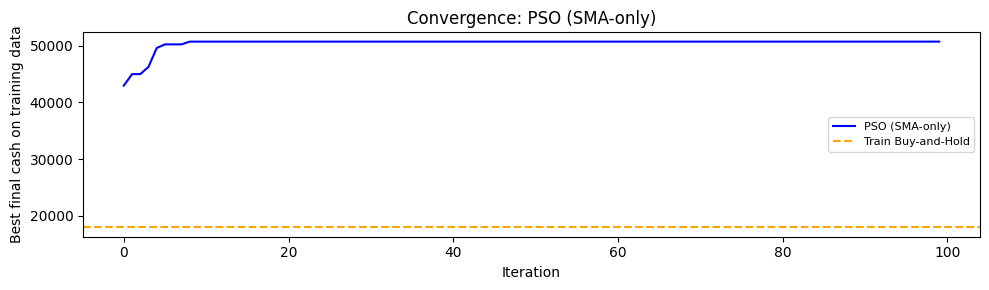


[Training] SFLA (SMA-only) | N=30, Iter=100, Seed=42
iter   10/100 best=$48,078.46 [1.3s]
iter   20/100 best=$50,989.83 [3.4s]
iter   30/100 best=$50,989.83 [5.2s]
iter   40/100 best=$50,989.83 [6.5s]
iter   50/100 best=$50,989.83 [7.9s]
iter   60/100 best=$50,989.83 [9.2s]
iter   70/100 best=$50,989.83 [10.5s]
iter   80/100 best=$50,989.83 [11.8s]
iter   90/100 best=$50,989.83 [13.1s]
iter  100/100 best=$50,989.83 [14.5s]
  Best training fitness / final cash: $50,989.83
  Training Buy-and-Hold baseline: $17,924.71
  Fitness evaluations: 6985


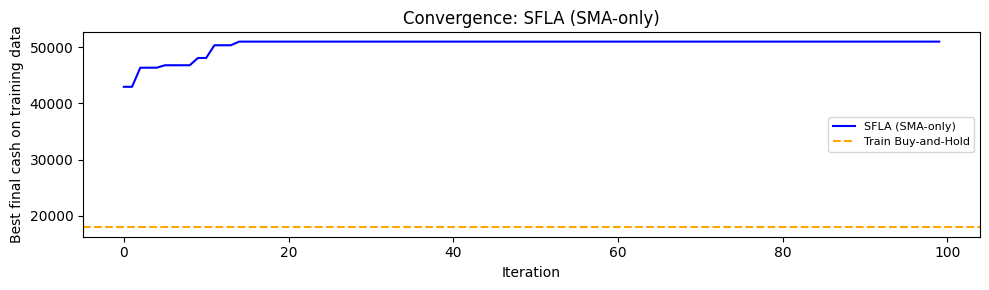


[Training] CS (SMA-only) | N=30, Iter=100, Seed=42
iter   10/100  best=$45,839.43 [0.3s]
iter   20/100  best=$45,839.43 [0.6s]
iter   30/100  best=$48,536.56 [1.0s]
iter   40/100  best=$48,536.56 [1.3s]
iter   50/100  best=$48,536.56 [1.6s]
iter   60/100  best=$48,536.56 [1.9s]
iter   70/100  best=$48,536.56 [2.2s]
iter   80/100  best=$48,536.56 [2.6s]
iter   90/100  best=$48,536.56 [2.8s]
iter  100/100  best=$48,536.56 [3.0s]
  Best training fitness / final cash: $48,536.56
  Training Buy-and-Hold baseline: $17,924.71
  Fitness evaluations: 930


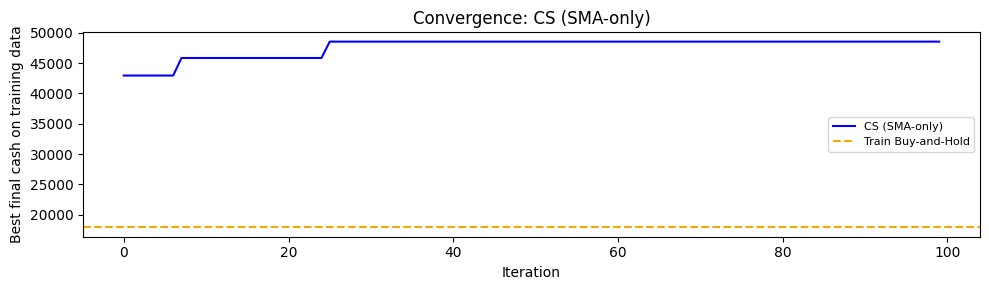


[Training] SMO (SMA-only) | N=30, Iter=100, Seed=42
iter   10/100  best=$49,228.90  [0.7s]
iter   20/100  best=$49,307.48  [1.3s]
iter   30/100  best=$49,307.48  [1.9s]
iter   40/100  best=$49,307.48  [2.5s]
iter   50/100  best=$49,307.48  [3.1s]
iter   60/100  best=$49,307.48  [3.8s]
iter   70/100  best=$49,307.48  [4.4s]
iter   80/100  best=$49,307.48  [5.0s]
iter   90/100  best=$49,307.48  [5.6s]
iter  100/100  best=$49,307.48  [6.2s]
  Best training fitness / final cash: $49,307.48
  Training Buy-and-Hold baseline: $17,924.71
  Fitness evaluations: 3000


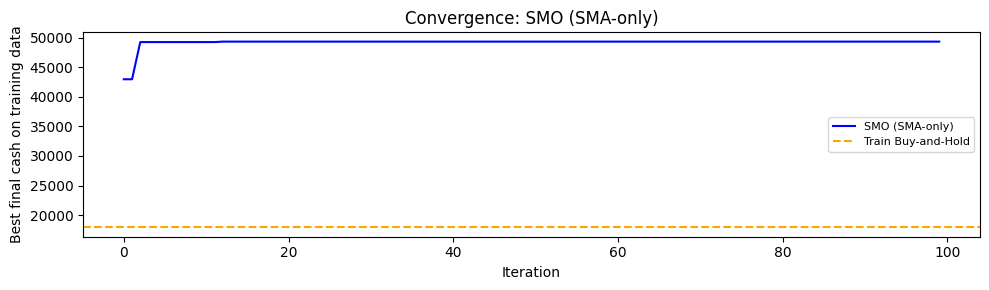

In [26]:
pso_sma_only = run_training(
    PSO,
    config='sma_only',
    N=30,
    max_iter=100,
    label='PSO (SMA-only)',
    seed=42
)

sfla_sma_only = run_training(
    SFLA,
    config='sma_only',
    N=30,
    max_iter=100,
    label='SFLA (SMA-only)',
    seed=42
)

cs_sma_only = run_training(
    cuckoo_search,
    config='sma_only',
    N=30,
    max_iter=100,
    label='CS (SMA-only)',
    seed=42
)

smo_sma_only = run_training(
    slime_mould,
    config='sma_only',
    N=30,
    max_iter=100,
    label='SMO (SMA-only)',
    seed=42
)

### 8.3 Show SMA-Only Run Results

Each SMA-only run is inspected after training. This shows the trading signals, equity curve, and main metrics for each algorithm.


PSO (SMA-only) [Training]
  Final cash: $50,717.21
  Buy-and-Hold: $17,924.71
  vs Buy-and-Hold: 282.95%
  Return: 4971.72%
  Max drawdown: -64.17%
  Exposure: 58.44%
  Trades: 3 buys, 3 sells


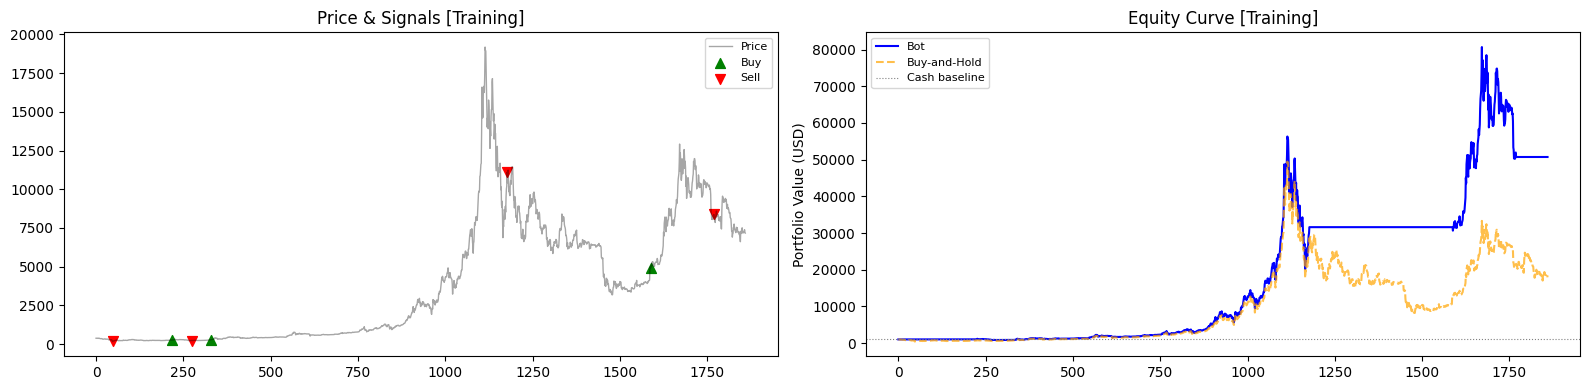


SFLA (SMA-only) [Training]
  Final cash: $50,989.83
  Buy-and-Hold: $17,924.71
  vs Buy-and-Hold: 284.47%
  Return: 4998.98%
  Max drawdown: -64.17%
  Exposure: 58.33%
  Trades: 3 buys, 3 sells


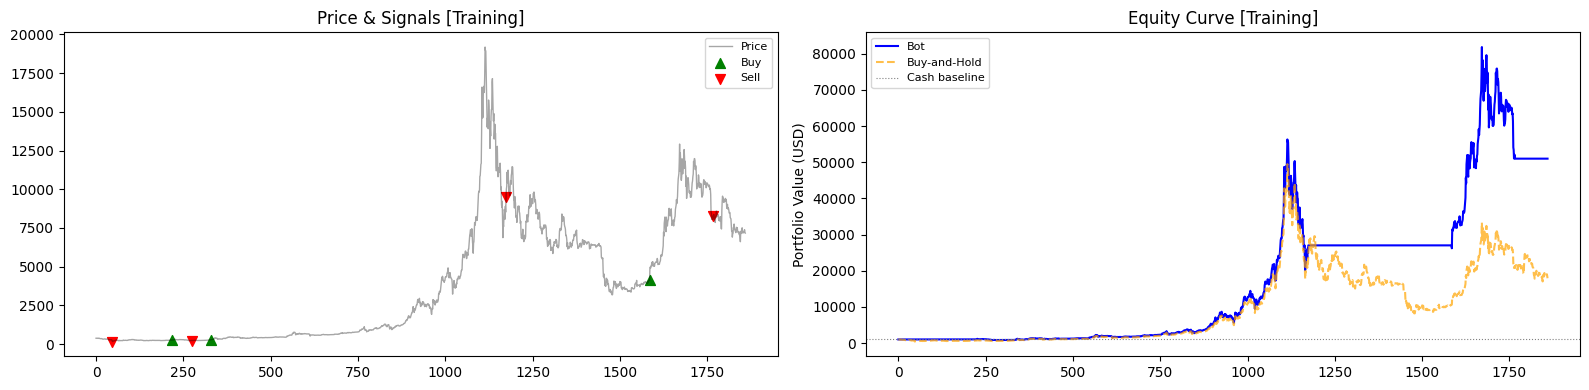


CS (SMA-only) [Training]
  Final cash: $48,536.56
  Buy-and-Hold: $17,924.71
  vs Buy-and-Hold: 270.78%
  Return: 4753.66%
  Max drawdown: -64.17%
  Exposure: 58.66%
  Trades: 3 buys, 3 sells


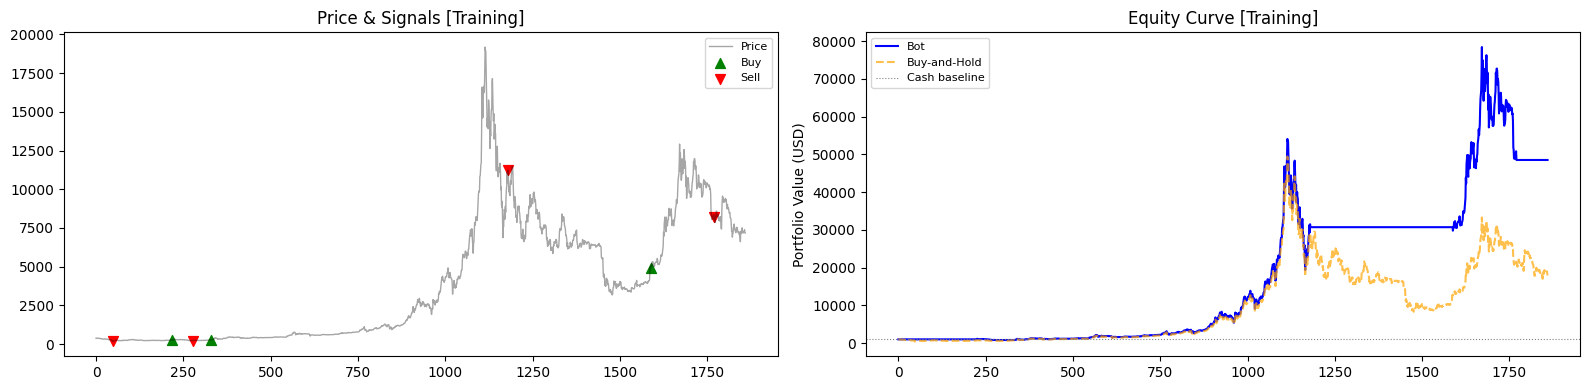


SMO (SMA-only) [Training]
  Final cash: $49,307.48
  Buy-and-Hold: $17,924.71
  vs Buy-and-Hold: 275.08%
  Return: 4830.75%
  Max drawdown: -64.17%
  Exposure: 59.30%
  Trades: 3 buys, 3 sells


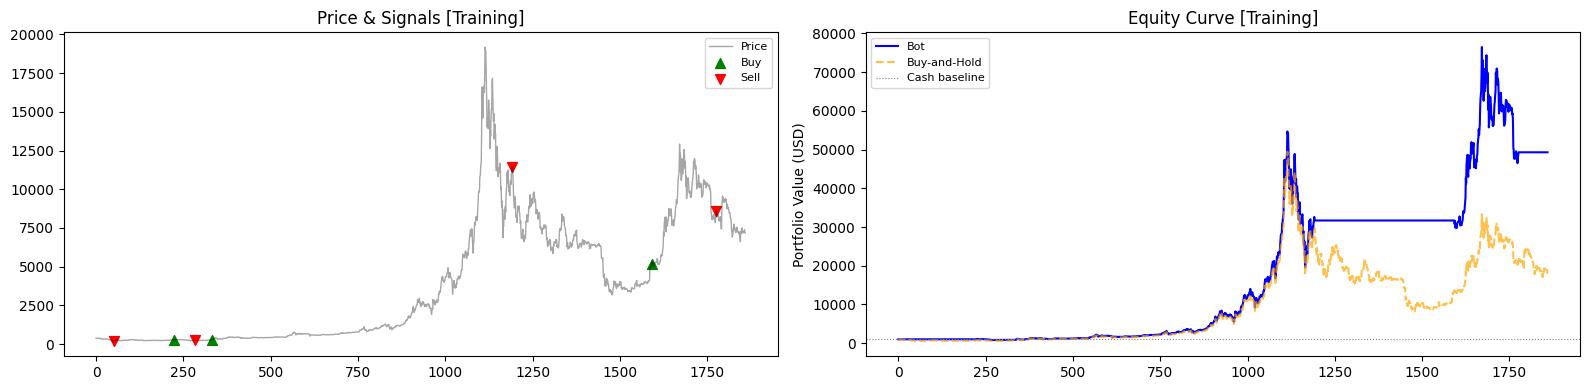

({'final_cash': np.float64(49307.48327599883),
  'n_buys': 3,
  'n_sells': 3,
  'equity_curve': array([ 1000.      ,  1000.      ,  1000.      , ..., 49307.483276,
         49307.483276, 49307.483276]),
  'position': array([0., 0., 0., ..., 0., 0., 0.])},
 {'Final Cash': np.float64(49307.48327599883),
  'Return (%)': np.float64(4830.748327599883),
  'Buy-and-Hold': np.float64(17924.710120123313),
  'vs BnH (%)': np.float64(275.0810637693014),
  'Max Drawdown (%)': np.float64(-64.17370847487305),
  'Exposure (%)': np.float64(59.30107526881721),
  'Buys': 3,
  'Sells': 3})

In [27]:
show_results(pso_sma_only, P_train, dataset_label='Training')
show_results(sfla_sma_only, P_train, dataset_label='Training')
show_results(cs_sma_only, P_train, dataset_label='Training')
show_results(smo_sma_only, P_train, dataset_label='Training')

### 8.4 Train Combined Moving-Average Runs

These runs use the `MAs_combined` search space. The algorithms can combine SMA, LMA, and EMA filters, so the search space is larger and more flexible.


[Training] PSO (MAs-combined) | N=30, Iter=100, Seed=42
iter   10/100 best=$54,627.79 [0.6s]
iter   20/100 best=$61,390.00 [1.2s]
iter   30/100 best=$61,407.39 [1.9s]
iter   40/100 best=$61,407.39 [3.0s]
iter   50/100 best=$61,407.39 [4.0s]
iter   60/100 best=$61,407.39 [4.8s]
iter   70/100 best=$61,407.39 [5.4s]
iter   80/100 best=$61,407.39 [5.9s]
iter   90/100 best=$61,407.39 [6.5s]
iter  100/100 best=$61,407.39 [7.4s]
  Best training fitness / final cash: $61,407.39
  Training Buy-and-Hold baseline: $17,924.71
  Fitness evaluations: 3000


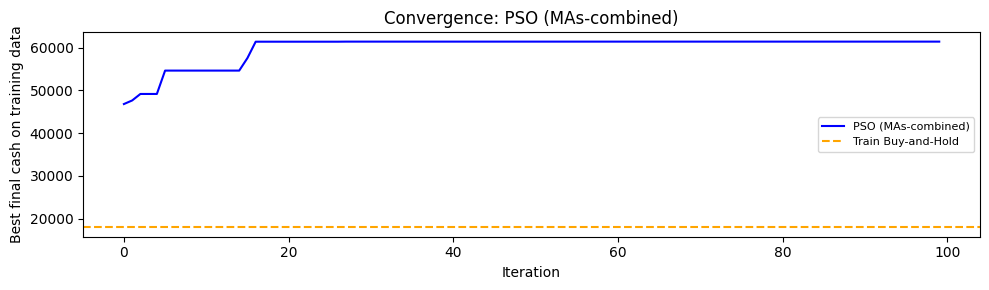


[Training] SFLA (MAs-combined) | N=30, Iter=100, Seed=42
iter   10/100 best=$49,405.75 [1.5s]
iter   20/100 best=$58,982.06 [2.9s]
iter   30/100 best=$59,516.37 [4.1s]
iter   40/100 best=$59,908.24 [5.3s]
iter   50/100 best=$60,496.78 [6.6s]
iter   60/100 best=$60,496.78 [8.8s]
iter   70/100 best=$60,496.78 [10.5s]
iter   80/100 best=$60,496.78 [11.7s]
iter   90/100 best=$60,496.78 [12.9s]
iter  100/100 best=$60,496.78 [14.2s]
  Best training fitness / final cash: $60,496.78
  Training Buy-and-Hold baseline: $17,924.71
  Fitness evaluations: 6688


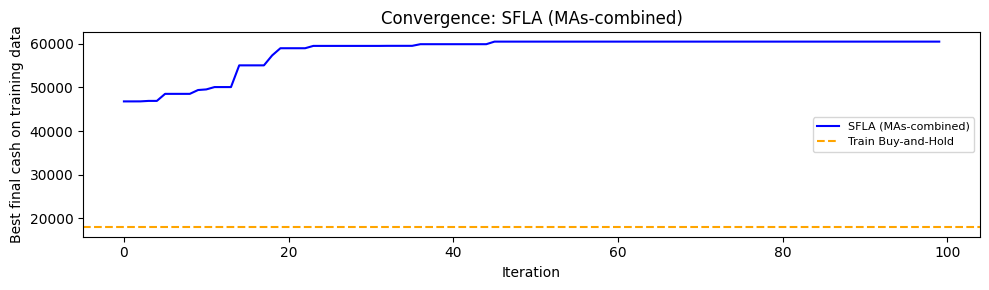


[Training] CS (MAs-combined) | N=30, Iter=100, Seed=42
iter   10/100  best=$46,801.17 [0.2s]
iter   20/100  best=$50,736.50 [0.3s]
iter   30/100  best=$50,736.50 [0.5s]
iter   40/100  best=$52,197.05 [0.7s]
iter   50/100  best=$52,197.05 [0.9s]
iter   60/100  best=$52,197.05 [1.0s]
iter   70/100  best=$52,197.05 [1.2s]
iter   80/100  best=$52,197.05 [1.4s]
iter   90/100  best=$52,825.21 [1.6s]
iter  100/100  best=$52,825.21 [1.7s]
  Best training fitness / final cash: $52,825.21
  Training Buy-and-Hold baseline: $17,924.71
  Fitness evaluations: 930


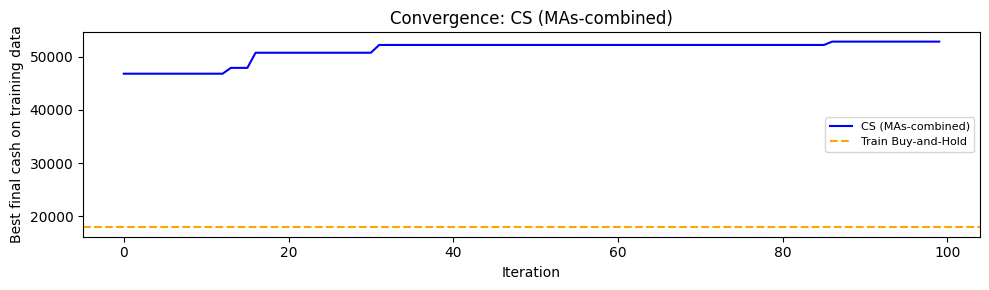


[Training] SMO (MAs-combined) | N=30, Iter=100, Seed=42
iter   10/100  best=$52,752.35  [0.6s]
iter   20/100  best=$59,501.90  [1.2s]
iter   30/100  best=$59,501.90  [1.8s]
iter   40/100  best=$60,585.52  [2.4s]
iter   50/100  best=$62,995.37  [3.0s]
iter   60/100  best=$62,995.37  [3.7s]
iter   70/100  best=$63,176.05  [4.8s]
iter   80/100  best=$63,176.05  [5.9s]
iter   90/100  best=$63,176.05  [6.7s]
iter  100/100  best=$63,176.05  [7.3s]
  Best training fitness / final cash: $63,176.05
  Training Buy-and-Hold baseline: $17,924.71
  Fitness evaluations: 3000


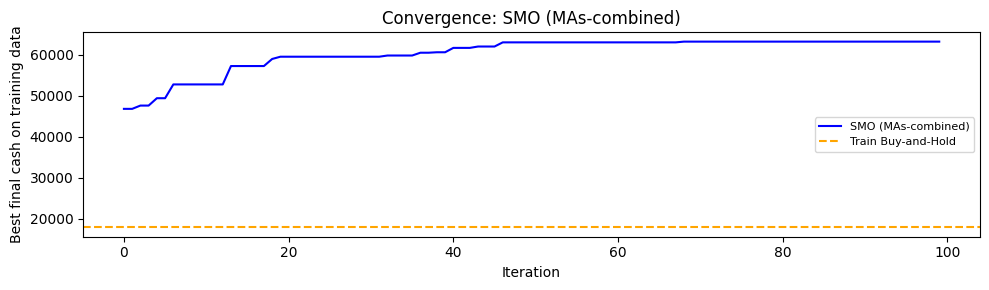

In [28]:
pso_ma_combined = run_training(
    PSO,
    config='MAs_combined',
    N=30,
    max_iter=100,
    label='PSO (MAs-combined)',
    seed=42
)

sfla_ma_combined = run_training(
    SFLA,
    config='MAs_combined',
    N=30,
    max_iter=100,
    label='SFLA (MAs-combined)',
    seed=42
)

cs_ma_combined = run_training(
    cuckoo_search,
    config='MAs_combined',
    N=30,
    max_iter=100,
    label='CS (MAs-combined)',
    seed=42
)

smo_ma_combined = run_training(
    slime_mould,
    config='MAs_combined',
    N=30,
    max_iter=100,
    label='SMO (MAs-combined)',
    seed=42
)

### 8.5 Show Combined Moving-Average Run Results

Each combined moving-average run is inspected after training. This helps check how the more flexible strategies behave before comparing all runs together.


PSO (MAs-combined) [Training]
  Final cash: $61,407.39
  Buy-and-Hold: $17,924.71
  vs Buy-and-Hold: 342.59%
  Return: 6040.74%
  Max drawdown: -64.17%
  Exposure: 58.66%
  Trades: 3 buys, 3 sells


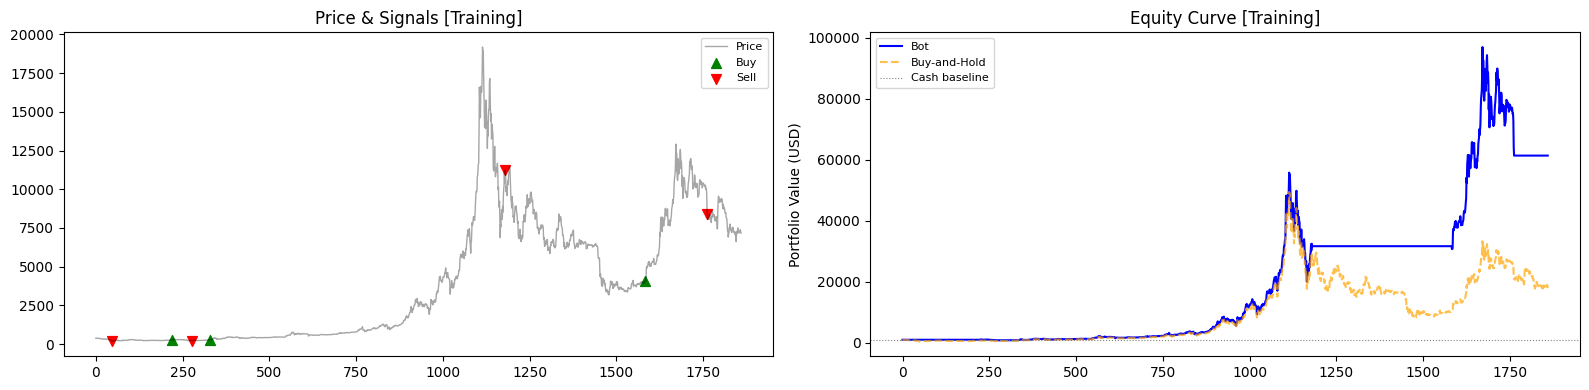


SFLA (MAs-combined) [Training]
  Final cash: $60,496.78
  Buy-and-Hold: $17,924.71
  vs Buy-and-Hold: 337.50%
  Return: 5949.68%
  Max drawdown: -64.17%
  Exposure: 58.76%
  Trades: 3 buys, 3 sells


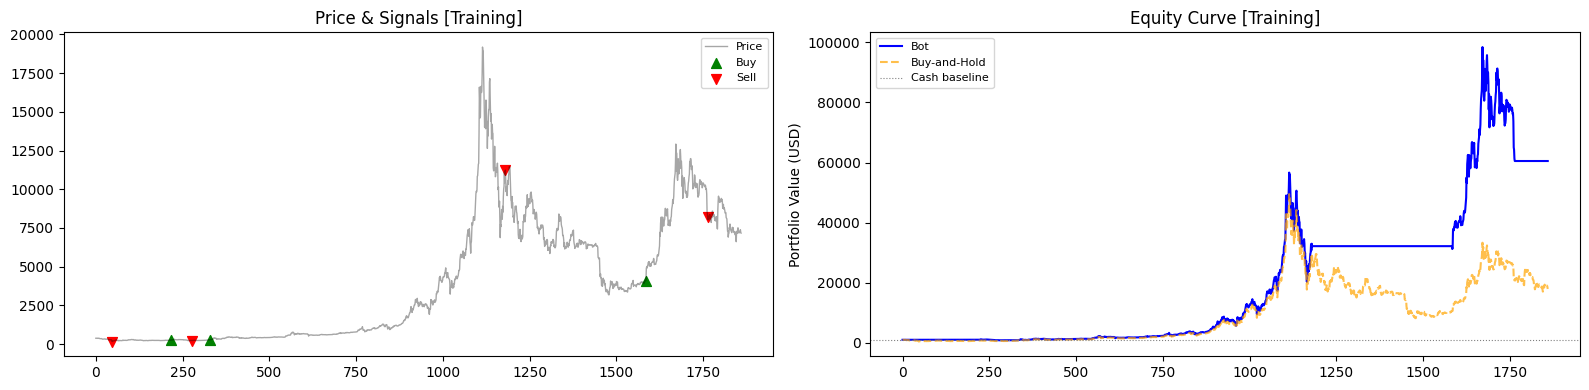


CS (MAs-combined) [Training]
  Final cash: $52,825.21
  Buy-and-Hold: $17,924.71
  vs Buy-and-Hold: 294.71%
  Return: 5182.52%
  Max drawdown: -54.76%
  Exposure: 55.86%
  Trades: 5 buys, 5 sells


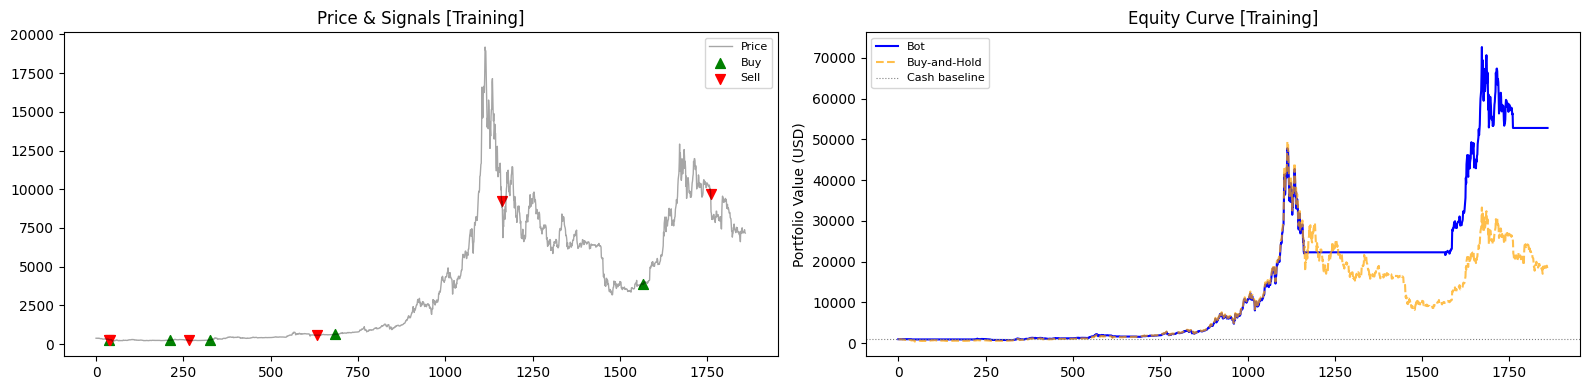


SMO (MAs-combined) [Training]
  Final cash: $63,176.05
  Buy-and-Hold: $17,924.71
  vs Buy-and-Hold: 352.45%
  Return: 6217.61%
  Max drawdown: -64.17%
  Exposure: 57.63%
  Trades: 4 buys, 4 sells


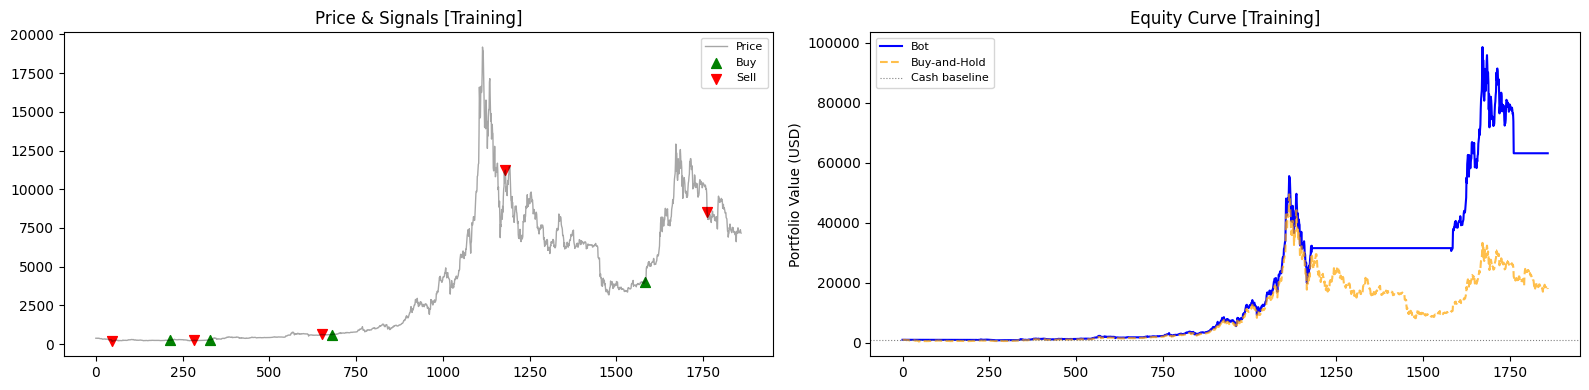

({'final_cash': np.float64(63176.053452727385),
  'n_buys': 4,
  'n_sells': 4,
  'equity_curve': array([ 1000.        ,  1000.        ,  1000.        , ...,
         63176.05345273, 63176.05345273, 63176.05345273]),
  'position': array([0., 0., 0., ..., 0., 0., 0.])},
 {'Final Cash': np.float64(63176.053452727385),
  'Return (%)': np.float64(6217.605345272739),
  'Buy-and-Hold': np.float64(17924.710120123313),
  'vs BnH (%)': np.float64(352.4523020419856),
  'Max Drawdown (%)': np.float64(-64.17370847487307),
  'Exposure (%)': np.float64(57.634408602150536),
  'Buys': 4,
  'Sells': 4})

In [29]:
show_results(pso_ma_combined, P_train, dataset_label='Training')
show_results(sfla_ma_combined, P_train, dataset_label='Training')
show_results(cs_ma_combined, P_train, dataset_label='Training')
show_results(smo_ma_combined, P_train, dataset_label='Training')

### 8.6 Compare Results on Training Data

The training runs are then compared together in one equity curve plot and summary table.

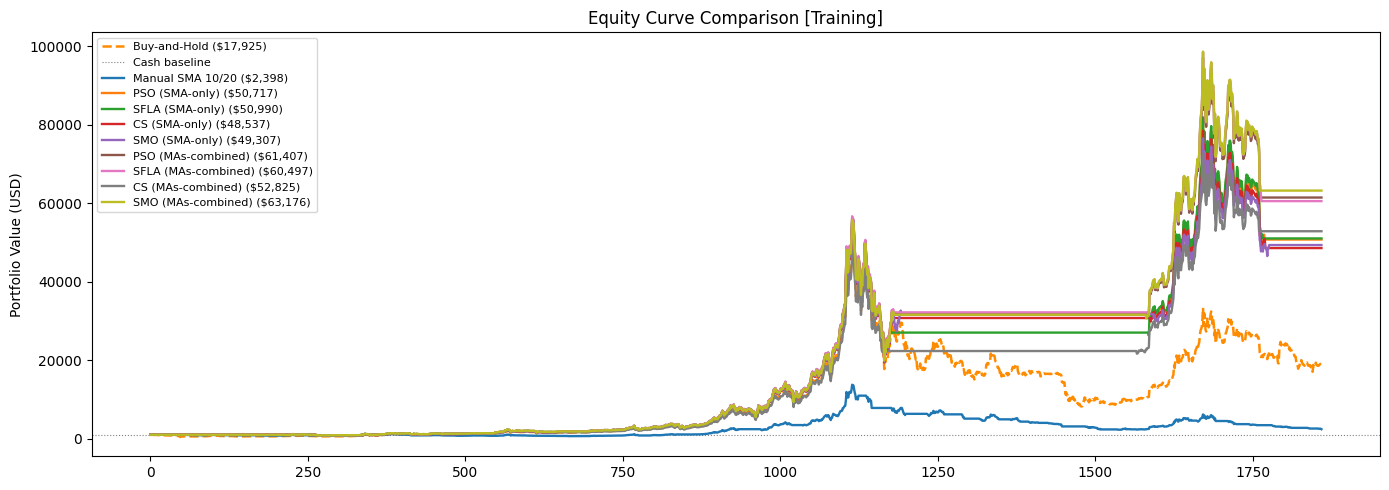


Summary [Training]


,Label,Algo,Config,Seed,Eval Count,Train Fitness,Final Cash,Buy-and-Hold,vs BnH (%),Return (%),Max Drawdown (%),Exposure (%),Buys,Sells
0,Manual SMA 10/20,Manual baseline,manual_sma,NaN,0,NaN,2398.333043,17924.71012,13.380038,139.833304,-83.536698,56.827957,46,45
1,PSO (SMA-only),PSO,sma_only,42.0,3000,50717.211171,50717.211171,17924.71012,282.945782,4971.721117,-64.173708,58.440860,3,3
2,SFLA (SMA-only),SFLA,sma_only,42.0,6985,50989.827330,50989.827330,17924.71012,284.466677,4998.982733,-64.173708,58.333333,3,3
3,CS (SMA-only),cuckoo_search,sma_only,42.0,930,48536.557485,48536.557485,17924.71012,270.780153,4753.655749,-64.173708,58.655914,3,3
4,SMO (SMA-only),slime_mould,sma_only,42.0,3000,49307.483276,49307.483276,17924.71012,275.081064,4830.748328,-64.173708,59.301075,3,3
5,PSO (MAs-combined),PSO,MAs_combined,42.0,3000,61407.389076,61407.389076,17924.71012,342.585117,6040.738908,-64.173708,58.655914,3,3
6,SFLA (MAs-combined),SFLA,MAs_combined,42.0,6688,60496.775654,60496.775654,17924.71012,337.504904,5949.677565,-64.173708,58.763441,3,3
7,CS (MAs-combined),cuckoo_search,MAs_combined,42.0,930,52825.213835,52825.213835,17924.71012,294.706098,5182.521384,-54.759687,55.860215,5,5
8,SMO (MAs-combined),slime_mould,MAs_combined,42.0,3000,63176.053453,63176.053453,17924.71012,352.452302,6217.605345,-64.173708,57.634409,4,4


In [30]:
train_summary = compare_runs(
    manual_sma,
    pso_sma_only,
    sfla_sma_only,
    cs_sma_only,
    smo_sma_only,
    pso_ma_combined,
    sfla_ma_combined,
    cs_ma_combined,
    smo_ma_combined,
    P=P_train,
    dataset_label='Training'
)

### 8.7 Evaluate Results on Test Data

The trained runs are evaluated again on the test data to check performance on unseen prices.

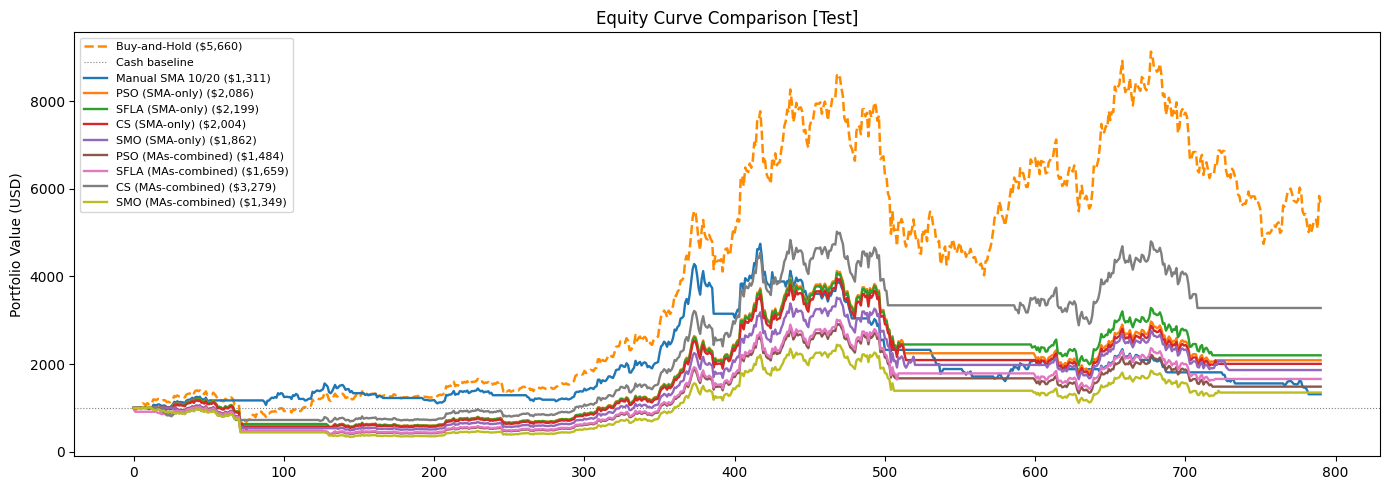


Summary [Test]


,Label,Algo,Config,Seed,Eval Count,Train Fitness,Final Cash,Buy-and-Hold,vs BnH (%),Return (%),Max Drawdown (%),Exposure (%),Buys,Sells
0,Manual SMA 10/20,Manual baseline,manual_sma,NaN,0,NaN,1311.274577,5660.263187,23.166318,31.127458,-72.361541,59.039191,19,19
1,PSO (SMA-only),PSO,sma_only,42.0,3000,50717.211171,2086.333823,5660.263187,36.859308,108.633382,-56.723596,69.785082,3,3
2,SFLA (SMA-only),SFLA,sma_only,42.0,6985,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3
3,CS (SMA-only),cuckoo_search,sma_only,42.0,930,48536.557485,2003.522456,5660.263187,35.396277,100.352246,-56.399343,69.532238,3,3
4,SMO (SMA-only),slime_mould,sma_only,42.0,3000,49307.483276,1862.351784,5660.263187,32.902212,86.235178,-54.417622,69.911504,3,3
5,PSO (MAs-combined),PSO,MAs_combined,42.0,3000,61407.389076,1484.033066,5660.263187,26.218446,48.403307,-62.321750,69.911504,4,4
6,SFLA (MAs-combined),SFLA,MAs_combined,42.0,6688,60496.775654,1659.493129,5660.263187,29.318303,65.949313,-60.532118,70.290771,4,4
7,CS (MAs-combined),cuckoo_search,MAs_combined,42.0,930,52825.213835,3278.993835,5660.263187,57.930060,227.899384,-42.564366,69.026549,5,5
8,SMO (MAs-combined),slime_mould,MAs_combined,42.0,3000,63176.053453,1349.298151,5660.263187,23.838081,34.929815,-67.325835,70.543616,6,6


In [31]:
test_summary = compare_runs(
    manual_sma,
    pso_sma_only,
    sfla_sma_only,
    cs_sma_only,
    smo_sma_only,
    pso_ma_combined,
    sfla_ma_combined,
    cs_ma_combined,
    smo_ma_combined,
    P=P_test,
    dataset_label='Test'
)

### 8.8 Show Selected Test Results

The strongest or most interesting test runs was CS_MA_COMBINED


CS (MAs-combined) [Test]
  Final cash: $3,278.99
  Buy-and-Hold: $5,660.26
  vs Buy-and-Hold: 57.93%
  Return: 227.90%
  Max drawdown: -42.56%
  Exposure: 69.03%
  Trades: 5 buys, 5 sells


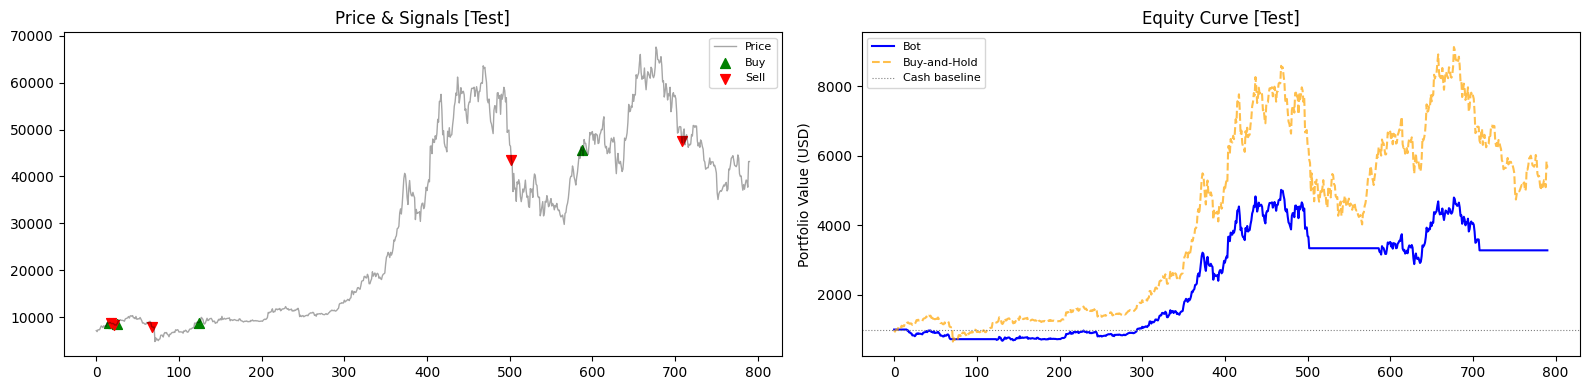

,Signal,SMA weight,LMA weight,EMA weight,SMA window,LMA window,EMA window,EMA alpha
0,Fast,0.040714,0.873660,0.545976,23,32,23,0.867890
1,Slow,0.906952,0.425903,0.290741,110,187,48,0.610026


In [32]:
show_results(cs_ma_combined, P_test, dataset_label='Test')
parameter_summary(cs_ma_combined)

## 9. Seed Robustness Experiment

This section repeats the optimisation runs using different random seeds. Both `sma_only` and `MAs_combined` are tested, so the results can show whether each algorithm is stable across different search spaces.

This is useful because one result from a single seed may be lucky or unlucky.

In [33]:
seed_list = [1, 7, 21, 42, 99]

seed_runs = []

for seed in seed_list:
    # SMA-only runs
    seed_runs.append(
        run_training(
            PSO,
            config='sma_only',
            N=30,
            max_iter=100,
            label=f'PSO (SMA-only) seed {seed}',
            seed=seed,
            verbose=False,
            show_plot=False
        )
    )

    seed_runs.append(
        run_training(
            SFLA,
            config='sma_only',
            N=30,
            max_iter=100,
            label=f'SFLA (SMA-only) seed {seed}',
            seed=seed,
            verbose=False,
            show_plot=False
        )
    )

    seed_runs.append(
        run_training(
            cuckoo_search,
            config='sma_only',
            N=30,
            max_iter=100,
            label=f'CS (SMA-only) seed {seed}',
            seed=seed,
            verbose=False,
            show_plot=False
        )
    )

    seed_runs.append(
        run_training(
            slime_mould,
            config='sma_only',
            N=30,
            max_iter=100,
            label=f'SMO (SMA-only) seed {seed}',
            seed=seed,
            verbose=False,
            show_plot=False
        )
    )

    # MAs-combined runs
    seed_runs.append(
        run_training(
            PSO,
            config='MAs_combined',
            N=30,
            max_iter=100,
            label=f'PSO (MAs-combined) seed {seed}',
            seed=seed,
            verbose=False,
            show_plot=False
        )
    )

    seed_runs.append(
        run_training(
            SFLA,
            config='MAs_combined',
            N=30,
            max_iter=100,
            label=f'SFLA (MAs-combined) seed {seed}',
            seed=seed,
            verbose=False,
            show_plot=False
        )
    )

    seed_runs.append(
        run_training(
            cuckoo_search,
            config='MAs_combined',
            N=30,
            max_iter=100,
            label=f'CS (MAs-combined) seed {seed}',
            seed=seed,
            verbose=False,
            show_plot=False
        )
    )

    seed_runs.append(
        run_training(
            slime_mould,
            config='MAs_combined',
            N=30,
            max_iter=100,
            label=f'SMO (MAs-combined) seed {seed}',
            seed=seed,
            verbose=False,
            show_plot=False
        )
    )

iter   10/100 best=$50,989.83 [0.6s]
iter   20/100 best=$50,989.83 [1.1s]
iter   30/100 best=$50,989.83 [1.7s]
iter   40/100 best=$50,989.83 [2.2s]
iter   50/100 best=$50,989.83 [2.7s]
iter   60/100 best=$50,989.83 [3.3s]
iter   70/100 best=$50,989.83 [3.8s]
iter   80/100 best=$50,989.83 [4.3s]
iter   90/100 best=$50,989.83 [4.9s]
iter  100/100 best=$50,989.83 [5.4s]
iter   10/100 best=$50,989.83 [1.8s]
iter   20/100 best=$50,989.83 [3.9s]
iter   30/100 best=$50,989.83 [5.2s]
iter   40/100 best=$50,989.83 [6.5s]
iter   50/100 best=$50,989.83 [7.8s]
iter   60/100 best=$50,989.83 [9.1s]
iter   70/100 best=$50,989.83 [10.4s]
iter   80/100 best=$50,989.83 [11.7s]
iter   90/100 best=$50,989.83 [13.0s]
iter  100/100 best=$50,989.83 [15.1s]
iter   10/100  best=$43,683.49 [0.3s]
iter   20/100  best=$43,683.49 [0.6s]
iter   30/100  best=$44,037.82 [0.9s]
iter   40/100  best=$47,463.64 [1.2s]
iter   50/100  best=$47,463.64 [1.4s]
iter   60/100  best=$49,596.43 [1.6s]
iter   70/100  best=$50,344.

This evaluates all seed runs on the training and test datasets so the results can be compared consistently.

,Label,Algo,Config,Dataset,Seed,N,Max Iter,Eval Count,Train Fitness,Final Cash,Buy-and-Hold,vs BnH (%),Return (%),Max Drawdown (%),Exposure (%),Buys,Sells
0,PSO (SMA-only) seed 1,PSO,sma_only,Training - Seed Robustness,1,30,100,3000,50989.827330,50989.827330,17924.71012,284.466677,4998.982733,-64.173708,58.333333,3,3
1,SFLA (SMA-only) seed 1,SFLA,sma_only,Training - Seed Robustness,1,30,100,6927,50989.827330,50989.827330,17924.71012,284.466677,4998.982733,-64.173708,58.333333,3,3
2,CS (SMA-only) seed 1,cuckoo_search,sma_only,Training - Seed Robustness,1,30,100,930,50344.351259,50344.351259,17924.71012,280.865637,4934.435126,-64.173708,58.333333,3,3
3,SMO (SMA-only) seed 1,slime_mould,sma_only,Training - Seed Robustness,1,30,100,3000,50989.827330,50989.827330,17924.71012,284.466677,4998.982733,-64.173708,58.333333,3,3
4,PSO (MAs-combined) seed 1,PSO,MAs_combined,Training - Seed Robustness,1,30,100,3000,61407.389076,61407.389076,17924.71012,342.585117,6040.738908,-64.173708,58.655914,3,3
5,SFLA (MAs-combined) seed 1,SFLA,MAs_combined,Training - Seed Robustness,1,30,100,6808,60902.778026,60902.778026,17924.71012,339.769947,5990.277803,-64.173708,58.763441,3,3
6,CS (MAs-combined) seed 1,cuckoo_search,MAs_combined,Training - Seed Robustness,1,30,100,930,54323.835336,54323.835336,17924.71012,303.066744,5332.383534,-64.173708,58.655914,3,3
7,SMO (MAs-combined) seed 1,slime_mould,MAs_combined,Training - Seed Robustness,1,30,100,3000,61234.100020,61234.100020,17924.71012,341.618356,6023.410002,-64.173708,57.419355,4,4
8,PSO (SMA-only) seed 7,PSO,sma_only,Training - Seed Robustness,7,30,100,3000,50989.827330,50989.827330,17924.71012,284.466677,4998.982733,-64.173708,58.333333,3,3
9,SFLA (SMA-only) seed 7,SFLA,sma_only,Training - Seed Robustness,7,30,100,6920,50717.211171,50717.211171,17924.71012,282.945782,4971.721117,-64.173708,58.440860,3,3


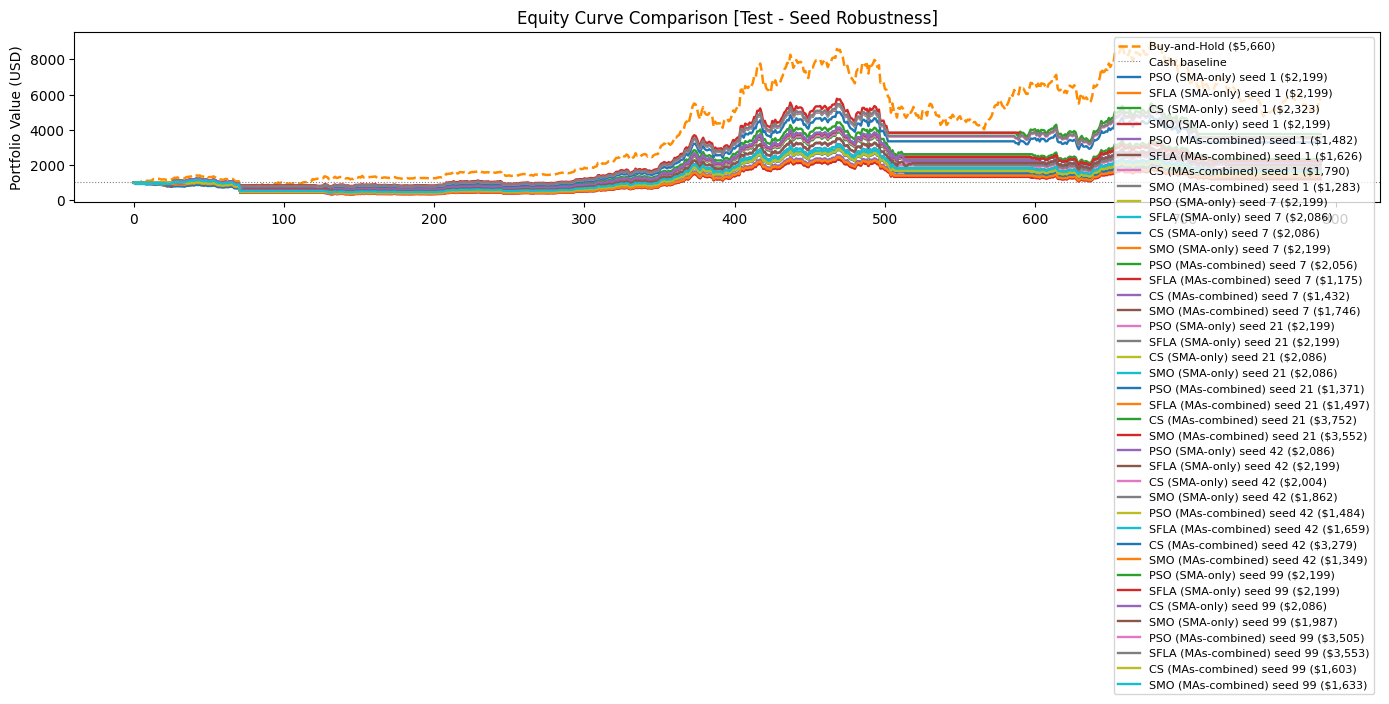


Summary [Test - Seed Robustness]


,Label,Algo,Config,Seed,Eval Count,Train Fitness,Final Cash,Buy-and-Hold,vs BnH (%),Return (%),Max Drawdown (%),Exposure (%),Buys,Sells
0,PSO (SMA-only) seed 1,PSO,sma_only,1,3000,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3
1,SFLA (SMA-only) seed 1,SFLA,sma_only,1,6927,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3
2,CS (SMA-only) seed 1,cuckoo_search,sma_only,1,930,50344.351259,2323.169497,5660.263187,41.043489,132.316950,-53.283951,69.532238,3,3
3,SMO (SMA-only) seed 1,slime_mould,sma_only,1,3000,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3
4,PSO (MAs-combined) seed 1,PSO,MAs_combined,1,3000,61407.389076,1482.008720,5660.263187,26.182682,48.200872,-62.321750,70.290771,4,4
5,SFLA (MAs-combined) seed 1,SFLA,MAs_combined,1,6808,60902.778026,1626.391609,5660.263187,28.733498,62.639161,-62.321750,70.290771,3,3
6,CS (MAs-combined) seed 1,cuckoo_search,MAs_combined,1,930,54323.835336,1789.892495,5660.263187,31.622072,78.989250,-58.841017,70.417193,3,3
7,SMO (MAs-combined) seed 1,slime_mould,MAs_combined,1,3000,61234.100020,1283.310860,5660.263187,22.672282,28.331086,-68.122209,70.037927,6,6
8,PSO (SMA-only) seed 7,PSO,sma_only,7,3000,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3
9,SFLA (SMA-only) seed 7,SFLA,sma_only,7,6920,50717.211171,2086.333823,5660.263187,36.859308,108.633382,-56.723596,69.785082,3,3


In [34]:
seed_train_rows = []

for run in seed_runs:
    row, _ = summarise_run_result(
        run,
        P_train,
        dataset_label='Training - Seed Robustness'
    )
    seed_train_rows.append(row)

seed_train_summary = pd.DataFrame(seed_train_rows)

display(seed_train_summary)

seed_test_summary = compare_runs(
    *seed_runs,
    P=P_test,
    dataset_label='Test - Seed Robustness'
)


Extra columns are added to separate the results by algorithm, search space, and seed. This makes it easier to group the results for the robustness analysis.

In [35]:
for summary_df in [seed_train_summary, seed_test_summary]:
    summary_df['Algorithm'] = summary_df['Label'].str.extract(
        r'^(PSO|SFLA|CS|SMO)'
    )

    summary_df['Search Space'] = summary_df['Label'].str.extract(
        r'\((SMA-only|MAs-combined)\)'
    )

    summary_df['Seed Used'] = summary_df['Label'].str.extract(
        r'seed (\d+)'
    ).astype(int)

display(seed_test_summary)


,Label,Algo,Config,Seed,Eval Count,Train Fitness,Final Cash,Buy-and-Hold,vs BnH (%),Return (%),Max Drawdown (%),Exposure (%),Buys,Sells,Algorithm,Search Space,Seed Used
0,PSO (SMA-only) seed 1,PSO,sma_only,1,3000,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3,PSO,SMA-only,1
1,SFLA (SMA-only) seed 1,SFLA,sma_only,1,6927,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3,SFLA,SMA-only,1
2,CS (SMA-only) seed 1,cuckoo_search,sma_only,1,930,50344.351259,2323.169497,5660.263187,41.043489,132.316950,-53.283951,69.532238,3,3,CS,SMA-only,1
3,SMO (SMA-only) seed 1,slime_mould,sma_only,1,3000,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3,SMO,SMA-only,1
4,PSO (MAs-combined) seed 1,PSO,MAs_combined,1,3000,61407.389076,1482.008720,5660.263187,26.182682,48.200872,-62.321750,70.290771,4,4,PSO,MAs-combined,1
5,SFLA (MAs-combined) seed 1,SFLA,MAs_combined,1,6808,60902.778026,1626.391609,5660.263187,28.733498,62.639161,-62.321750,70.290771,3,3,SFLA,MAs-combined,1
6,CS (MAs-combined) seed 1,cuckoo_search,MAs_combined,1,930,54323.835336,1789.892495,5660.263187,31.622072,78.989250,-58.841017,70.417193,3,3,CS,MAs-combined,1
7,SMO (MAs-combined) seed 1,slime_mould,MAs_combined,1,3000,61234.100020,1283.310860,5660.263187,22.672282,28.331086,-68.122209,70.037927,6,6,SMO,MAs-combined,1
8,PSO (SMA-only) seed 7,PSO,sma_only,7,3000,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3,PSO,SMA-only,7
9,SFLA (SMA-only) seed 7,SFLA,sma_only,7,6920,50717.211171,2086.333823,5660.263187,36.859308,108.633382,-56.723596,69.785082,3,3,SFLA,SMA-only,7


This table summarises how each algorithm and search space performed across different seeds. The mean shows overall performance, while the standard deviation shows how stable the results were.

In [36]:
seed_robustness_summary = seed_test_summary.groupby(
    ['Algorithm', 'Search Space']
).agg(
    Mean_Final_Cash=('Final Cash', 'mean'),
    Std_Final_Cash=('Final Cash', 'std'),
    Best_Final_Cash=('Final Cash', 'max'),
    Worst_Final_Cash=('Final Cash', 'min'),
    Mean_Return=('Return (%)', 'mean'),
    Mean_Drawdown=('Max Drawdown (%)', 'mean'),
    Mean_Eval_Count=('Eval Count', 'mean')
).reset_index()

display(seed_robustness_summary)

,Algorithm,Search Space,Mean_Final_Cash,Std_Final_Cash,Best_Final_Cash,Worst_Final_Cash,Mean_Return,Mean_Drawdown,Mean_Eval_Count
0,CS,MAs-combined,2371.077891,1065.348907,3751.609993,1432.171761,137.107789,-53.813974,930.0
1,CS,SMA-only,2117.138684,120.627693,2323.169497,2003.522456,111.713868,-55.970816,930.0
2,PSO,MAs-combined,1979.573199,893.786752,3504.859616,1371.297252,97.957320,-56.873779,3000.0
3,PSO,SMA-only,2176.595753,50.457953,2199.161235,2086.333823,117.659575,-54.676770,3000.0
4,SFLA,MAs-combined,1902.207825,942.606574,3553.302343,1175.332844,90.220783,-59.215895,6757.6
5,SFLA,SMA-only,2176.595753,50.457953,2199.161235,2086.333823,117.659575,-54.676770,6947.4
6,SMO,MAs-combined,1912.847940,936.479528,3552.362034,1283.310860,91.284794,-61.042077,3000.0
7,SMO,SMA-only,2066.711177,144.620202,2199.161235,1862.351784,106.671118,-54.777793,3000.0


The robustness score is calculated as mean final cash minus the standard deviation across seeds. It is only used as a simple comparison aid: a higher score means the setting has good average performance with lower seed-to-seed variation.

In [37]:
seed_robustness_summary['Robustness Score'] = (
    seed_robustness_summary['Mean_Final_Cash']
    - seed_robustness_summary['Std_Final_Cash']
)

seed_robustness_summary = seed_robustness_summary.sort_values(
    by='Robustness Score',
    ascending=False
)

display(seed_robustness_summary)

,Algorithm,Search Space,Mean_Final_Cash,Std_Final_Cash,Best_Final_Cash,Worst_Final_Cash,Mean_Return,Mean_Drawdown,Mean_Eval_Count,Robustness Score
3,PSO,SMA-only,2176.595753,50.457953,2199.161235,2086.333823,117.659575,-54.676770,3000.0,2126.137800
5,SFLA,SMA-only,2176.595753,50.457953,2199.161235,2086.333823,117.659575,-54.676770,6947.4,2126.137800
1,CS,SMA-only,2117.138684,120.627693,2323.169497,2003.522456,111.713868,-55.970816,930.0,1996.510991
7,SMO,SMA-only,2066.711177,144.620202,2199.161235,1862.351784,106.671118,-54.777793,3000.0,1922.090975
0,CS,MAs-combined,2371.077891,1065.348907,3751.609993,1432.171761,137.107789,-53.813974,930.0,1305.728985
2,PSO,MAs-combined,1979.573199,893.786752,3504.859616,1371.297252,97.957320,-56.873779,3000.0,1085.786447
6,SMO,MAs-combined,1912.847940,936.479528,3552.362034,1283.310860,91.284794,-61.042077,3000.0,976.368412
4,SFLA,MAs-combined,1902.207825,942.606574,3553.302343,1175.332844,90.220783,-59.215895,6757.6,959.601251


In [38]:
best_robust = seed_robustness_summary.iloc[0]

print('Best robust setting:')
print(f"Algorithm: {best_robust['Algorithm']}")
print(f"Search space: {best_robust['Search Space']}")
print(f"Mean final cash: ${best_robust['Mean_Final_Cash']:,.2f}")
print(f"Std final cash: ${best_robust['Std_Final_Cash']:,.2f}")
print(f"Robustness score: ${best_robust['Robustness Score']:,.2f}")

Best robust setting:
Algorithm: PSO
Search space: SMA-only
Mean final cash: $2,176.60
Std final cash: $50.46
Robustness score: $2,126.14


## 10. Main Result Comparison

This section compares the main result from the original test run with the seed robustness result. The goal is to avoid choosing a final algorithm only from one lucky seed.

The best single test run and the best robust setting are not necessarily the same. The single best result shows the highest outcome from one seed, while the robust result considers consistency across multiple seeds.

In [39]:
test_summary_sorted = test_summary.sort_values(
    by='Final Cash',
    ascending=False
)

display(test_summary_sorted)

,Label,Algo,Config,Seed,Eval Count,Train Fitness,Final Cash,Buy-and-Hold,vs BnH (%),Return (%),Max Drawdown (%),Exposure (%),Buys,Sells
7,CS (MAs-combined),cuckoo_search,MAs_combined,42.0,930,52825.213835,3278.993835,5660.263187,57.930060,227.899384,-42.564366,69.026549,5,5
2,SFLA (SMA-only),SFLA,sma_only,42.0,6985,50989.827330,2199.161235,5660.263187,38.852632,119.916124,-54.165064,69.785082,3,3
1,PSO (SMA-only),PSO,sma_only,42.0,3000,50717.211171,2086.333823,5660.263187,36.859308,108.633382,-56.723596,69.785082,3,3
3,CS (SMA-only),cuckoo_search,sma_only,42.0,930,48536.557485,2003.522456,5660.263187,35.396277,100.352246,-56.399343,69.532238,3,3
4,SMO (SMA-only),slime_mould,sma_only,42.0,3000,49307.483276,1862.351784,5660.263187,32.902212,86.235178,-54.417622,69.911504,3,3
6,SFLA (MAs-combined),SFLA,MAs_combined,42.0,6688,60496.775654,1659.493129,5660.263187,29.318303,65.949313,-60.532118,70.290771,4,4
5,PSO (MAs-combined),PSO,MAs_combined,42.0,3000,61407.389076,1484.033066,5660.263187,26.218446,48.403307,-62.321750,69.911504,4,4
8,SMO (MAs-combined),slime_mould,MAs_combined,42.0,3000,63176.053453,1349.298151,5660.263187,23.838081,34.929815,-67.325835,70.543616,6,6
0,Manual SMA 10/20,Manual baseline,manual_sma,NaN,0,NaN,1311.274577,5660.263187,23.166318,31.127458,-72.361541,59.039191,19,19


In [40]:
best_single_run = test_summary_sorted.iloc[0]

print('Best single test run:')
print(f"Label: {best_single_run['Label']}")
print(f"Final cash: ${best_single_run['Final Cash']:,.2f}")
print(f"vs Buy-and-Hold: {best_single_run['vs BnH (%)']:.2f}%")

Best single test run:
Label: CS (MAs-combined)
Final cash: $3,278.99
vs Buy-and-Hold: 57.93%


In [41]:
print('Best robust setting from seed experiment:')
print(f"Algorithm: {best_robust['Algorithm']}")
print(f"Search space: {best_robust['Search Space']}")
print(f"Mean final cash: ${best_robust['Mean_Final_Cash']:,.2f}")
print(f"Std final cash: ${best_robust['Std_Final_Cash']:,.2f}")

Best robust setting from seed experiment:
Algorithm: PSO
Search space: SMA-only
Mean final cash: $2,176.60
Std final cash: $50.46


## 11. Learned Parameter Interpretation

This checks the learned parameters from the strongest selected run. The parameter table shows how the optimiser configured the fast and slow moving-average signals.

In [42]:
all_runs = [
    manual_sma,
    pso_sma_only,
    sfla_sma_only,
    cs_sma_only,
    smo_sma_only,
    pso_ma_combined,
    sfla_ma_combined,
    cs_ma_combined,
    smo_ma_combined,
]

best_test_label = test_summary_sorted.iloc[0]['Label']

best_run = None

for run in all_runs:
    if run['label'] == best_test_label:
        best_run = run
        break

print(f'Best single test run: {best_test_label}')

if best_run is not None:
    display(parameter_summary(best_run))
else:
    print('Best run not found.')

Best single test run: CS (MAs-combined)


,Signal,SMA weight,LMA weight,EMA weight,SMA window,LMA window,EMA window,EMA alpha
0,Fast,0.040714,0.873660,0.545976,23,32,23,0.867890
1,Slow,0.906952,0.425903,0.290741,110,187,48,0.610026


In [43]:
best_robust_algorithm = best_robust['Algorithm']
best_robust_space = best_robust['Search Space']

matching_seed_rows = seed_test_summary[
    (seed_test_summary['Algorithm'] == best_robust_algorithm)
    & (seed_test_summary['Search Space'] == best_robust_space)
]

best_seed_label = matching_seed_rows.sort_values(
    by='Final Cash',
    ascending=False
).iloc[0]['Label']

best_seed_run = None

for run in seed_runs:
    if run['label'] == best_seed_label:
        best_seed_run = run
        break

print(f'Best seed run from best robust setting: {best_seed_label}')

if best_seed_run is not None:
    display(parameter_summary(best_seed_run))
else:
    print('Best seed run not found.')

Best seed run from best robust setting: PSO (SMA-only) seed 1


,Signal,SMA weight,LMA weight,EMA weight,SMA window,LMA window,EMA window,EMA alpha
0,Fast,1.0,0.0,0.0,25,39,2,0.99
1,Slow,1.0,0.0,0.0,146,56,78,0.01


## 12. Train vs Test Comparison

This comparison uses the seed robustness results rather than a single run.

Final cash is still included because it was the fitness value used during optimisation. However, the training and test periods are different, so the interpretation also uses return and performance relative to buy-and-hold.

The buy-and-hold comparison is especially useful because it shows how each bot performed against the market movement in that same period.


,Algorithm,Search Space,Mean_Train_Return,Mean_Test_Return,Mean_Train_vs_BnH,Mean_Test_vs_BnH,vs BnH Gap (%),Mean_Test_Drawdown,Mean_Eval_Count
0,CS,MAs-combined,5393.038243,137.107789,306.450604,41.889888,264.560716,-53.813974,930.0
3,PSO,SMA-only,4993.530410,117.659575,284.162498,38.453967,245.708531,-54.676770,3000.0
5,SFLA,SMA-only,4993.530410,117.659575,284.162498,38.453967,245.708531,-54.676770,6947.4
1,CS,SMA-only,4920.650845,111.713868,280.096627,37.403538,242.693089,-55.970816,930.0
7,SMO,SMA-only,4926.236648,106.671118,280.408253,36.512634,243.895619,-54.777793,3000.0
2,PSO,MAs-combined,5848.409807,97.957320,331.855286,34.973165,296.882121,-56.873779,3000.0
6,SMO,MAs-combined,5797.167537,91.284794,328.996536,33.794329,295.202207,-61.042077,3000.0
4,SFLA,MAs-combined,6161.063660,90.220783,349.297903,33.606349,315.691554,-59.215895,6757.6


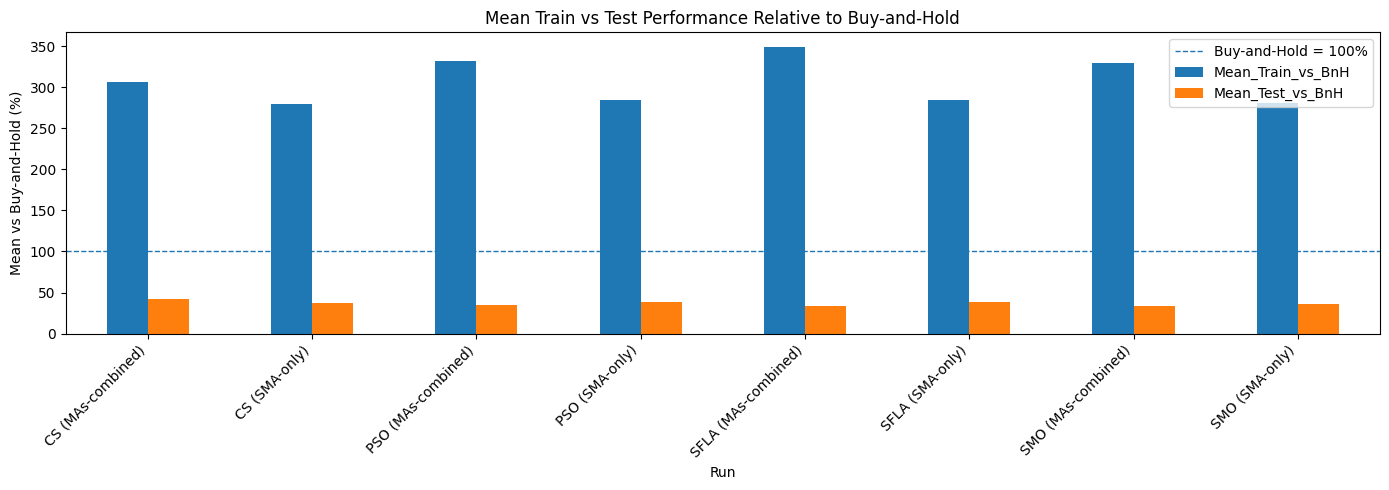

In [44]:
seed_train_grouped = seed_train_summary.groupby(
    ['Algorithm', 'Search Space']
).agg(
    Mean_Train_Final_Cash=('Final Cash', 'mean'),
    Std_Train_Final_Cash=('Final Cash', 'std'),
    Mean_Train_Return=('Return (%)', 'mean'),
    Mean_Train_vs_BnH=('vs BnH (%)', 'mean'),
    Mean_Train_Drawdown=('Max Drawdown (%)', 'mean'),
    Mean_Train_Exposure=('Exposure (%)', 'mean'),
    Mean_Train_Buys=('Buys', 'mean'),
    Mean_Train_Sells=('Sells', 'mean')
).reset_index()

seed_test_grouped = seed_test_summary.groupby(
    ['Algorithm', 'Search Space']
).agg(
    Mean_Test_Final_Cash=('Final Cash', 'mean'),
    Std_Test_Final_Cash=('Final Cash', 'std'),
    Mean_Test_Return=('Return (%)', 'mean'),
    Mean_Test_vs_BnH=('vs BnH (%)', 'mean'),
    Mean_Test_Drawdown=('Max Drawdown (%)', 'mean'),
    Mean_Test_Exposure=('Exposure (%)', 'mean'),
    Mean_Test_Buys=('Buys', 'mean'),
    Mean_Test_Sells=('Sells', 'mean'),
    Mean_Eval_Count=('Eval Count', 'mean')
).reset_index()

seed_train_test_compare = pd.merge(
    seed_train_grouped,
    seed_test_grouped,
    on=['Algorithm', 'Search Space']
)

seed_train_test_compare['Return Gap (%)'] = (
    seed_train_test_compare['Mean_Train_Return']
    - seed_train_test_compare['Mean_Test_Return']
)

seed_train_test_compare['vs BnH Gap (%)'] = (
    seed_train_test_compare['Mean_Train_vs_BnH']
    - seed_train_test_compare['Mean_Test_vs_BnH']
)

seed_train_test_compare['Drawdown Gap (%)'] = (
    seed_train_test_compare['Mean_Train_Drawdown']
    - seed_train_test_compare['Mean_Test_Drawdown']
)

# Display only the most important columns for interpretation.
train_test_display = seed_train_test_compare[
    [
        'Algorithm',
        'Search Space',
        'Mean_Train_Return',
        'Mean_Test_Return',
        'Mean_Train_vs_BnH',
        'Mean_Test_vs_BnH',
        'vs BnH Gap (%)',
        'Mean_Test_Drawdown',
        'Mean_Eval_Count'
    ]
].sort_values(
    by='Mean_Test_vs_BnH',
    ascending=False
)

display(train_test_display)

# Plot the main train/test comparison relative to Buy-and-Hold.
plot_df = seed_train_test_compare.copy()
plot_df['Run'] = plot_df['Algorithm'] + ' (' + plot_df['Search Space'] + ')'

bnh_plot_df = plot_df.set_index('Run')[
    ['Mean_Train_vs_BnH', 'Mean_Test_vs_BnH']
]

ax = bnh_plot_df.plot(kind='bar', figsize=(14, 5))
ax.axhline(100, linestyle='--', linewidth=1, label='Buy-and-Hold = 100%')

plt.ylabel('Mean vs Buy-and-Hold (%)')
plt.title('Mean Train vs Test Performance Relative to Buy-and-Hold')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

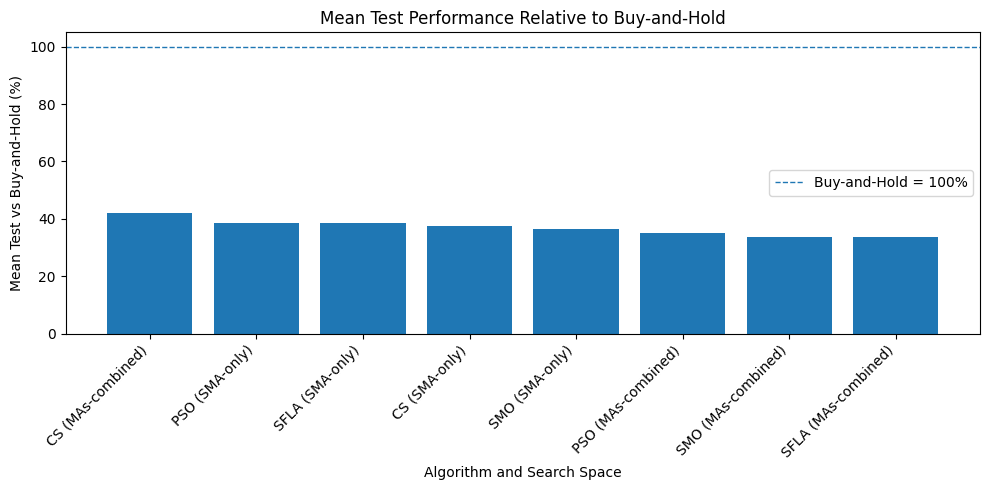

In [45]:
# Create label for each algorithm + search space
seed_test_grouped['Run'] = (
    seed_test_grouped['Algorithm']
    + ' ('
    + seed_test_grouped['Search Space']
    + ')'
)

# Sort by mean test performance
test_sorted = seed_test_grouped.sort_values(
    by='Mean_Test_vs_BnH',
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    test_sorted['Run'],
    test_sorted['Mean_Test_vs_BnH']
)

plt.axhline(
    100,
    linestyle='--',
    linewidth=1,
    label='Buy-and-Hold = 100%'
)

plt.title('Mean Test Performance Relative to Buy-and-Hold')
plt.ylabel('Mean Test vs Buy-and-Hold (%)')
plt.xlabel('Algorithm and Search Space')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()